In [1]:
# --- Imports / path setup (match your script) ---
import sys
from pathlib import Path
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))

from src.behavior_import.import_data import *
from src.behavior_import.extract_trials import *
from src.behavior_analysis.get_total_reversals import *
from src.behavior_analysis.get_good_reversal_info import *
from src.behavior_analysis.get_choice_probs_around_good_reversals import *
from src.behavior_analysis.split_good_reversals_by_best_change import *
from src.behavior_analysis.split_early_late_good_reversals import *
from src.behavior_visualization.plot_choice_probs_around_good_reversals import *

In [4]:
task = "open-field"
cohort = "cohort-01"
folder_name = "3x3_field_blocked_reward_bandit"

root = f"/Volumes/behrens/meg/{folder_name}/{cohort}/rawdata/"
subjects_data = import_data(root)
subjects_trials_by_problem = extract_trials_grouped_by_problem(subjects_data)

[WARN] Failed to read /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-01_id-MY_71_N/ses-08_date-20260204/behav/._MY_71_N-2026-02-04-153602.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-05_id-MY_72_L/ses-155_date-20260613/behav/._MY_72_L-2026-06-13-201430.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-02_id-MY_71_L/ses-54_date-20260305/behav/._MY_71_L-2026-03-05-150416.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-04_id-MY_72_N/ses-40_date-20260225/behav/._MY_72_N-2026-02-25-143929.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /

In [5]:
subject_trials_by_value_problem = {}
for problem_number in subjects_trials_by_problem.keys():
    problem = f"problem-{problem_number:02d}"
    if problem_number <= 11 and problem_number >= 5:
    # if problem_number >= 11:
        subjects_trials = subjects_trials_by_problem[problem_number]
        subject_trials_by_value_problem[problem_number] = subjects_trials

In [6]:
subject_trials_by_value_problem.keys()

dict_keys([5, 6, 7, 8, 9, 10, 11])

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

BEST_VALS = [2, 3, 4]       # y-axis
SECOND_VALS = [1, 2, 3]     # x-axis

def init_matrix(fill=np.nan):
    return pd.DataFrame(
        fill,
        index=pd.Index(BEST_VALS, name="best_value"),
        columns=pd.Index(SECOND_VALS, name="second_value"),
    )

def _compute_believed_value(choices, reward_magnitudes):
    """
    For each trial i, infer the believed rank of the chosen arm and the believed
    best/second magnitudes, based on last-seen arm values carried over continuously.

    Trials where any arm has not yet been visited are excluded (all fields None,
    n_seen < n_arms flagged via excluded=True). Once all arms have been visited
    at least once, every subsequent trial is included.

    Parameters
    ----------
    choices           : list[str]  — arm chosen on each trial
    reward_magnitudes : list[dict] — true arm->magnitude mapping per trial

    Returns
    -------
    list of dicts with keys:
        believed_best_mag   : float | None
        believed_second_mag : float | None
        believed_chosen_rank: str | None
        tied                : bool
        n_seen              : int
        excluded            : bool  — True if any arm was unseen on this trial
    """
    last_seen  = {}
    results    = []
    n_excluded = 0
    n_included = 0

    for i, rm in enumerate(reward_magnitudes):
        choice   = choices[i]
        all_arms = list(rm.keys())
        believed = {arm: last_seen[arm] for arm in all_arms if arm in last_seen}
        n_seen   = len(believed)

        if n_seen < len(all_arms):
            # at least one arm never visited — exclude this trial
            results.append({
                "believed_best_mag":    None,
                "believed_second_mag":  None,
                "believed_chosen_rank": None,
                "tied":                 False,
                "n_seen":               n_seen,
                "excluded":             True,
            })
            n_excluded += 1
        else:
            ranked = sorted(believed.items(), key=lambda x: (-x[1], str(x[0])))

            believed_best_mag   = ranked[0][1] if n_seen >= 1 else None
            believed_second_mag = ranked[1][1] if n_seen >= 2 else None

            believed_rank_of_choice = None
            for rank_idx, (arm, _) in enumerate(ranked):
                if arm == choice:
                    believed_rank_of_choice = ["best", "second", "third"][min(rank_idx, 2)]
                    break

            tied = (
                believed_best_mag is not None and
                believed_second_mag is not None and
                believed_best_mag == believed_second_mag
            )

            results.append({
                "believed_best_mag":    believed_best_mag,
                "believed_second_mag":  believed_second_mag,
                "believed_chosen_rank": believed_rank_of_choice,
                "tied":                 tied,
                "n_seen":               n_seen,
                "excluded":             False,
            })
            n_included += 1

        if choice and choice in rm:
            last_seen[choice] = rm[choice]

    total = n_included + n_excluded
    pct   = 100 * n_excluded / total if total > 0 else 0
    print(f"    Trials: {total} total | {n_included} included | "
          f"{n_excluded} excluded ({pct:.1f}%) — unseen arms")

    return results


def accumulate_choice_probs(subject_trials_by_value_problem, use_believed=False):
    """
    subject_trials_by_value_problem[problem][subject_id][session_id] = session_data

    session_data["trial_variables"] is a list with a single element: a dict of
    parallel lists, one value per trial. Keys include:
      - "reward_magnitudes" : list[dict]  — arm->magnitude per trial
      - "chosen_rank"       : list[str]   — "best"/"second"/"third" per trial
      - "choice"            : list[str]   — chosen arm label per trial

    Parameters
    ----------
    use_believed : bool
        False (default) — bin by true reward magnitudes and true chosen rank.
        True            — bin by believed magnitudes (last observed value per arm
                          before this trial), with arms re-ranked by believed
                          value to determine best/second and the chosen rank.
                          Trials where fewer than 2 arms have been visited, or
                          where the chosen arm has no believed value, are skipped.
                          Tied trials split contributions evenly across best/second.

    Returns
    -------
    overall_best_prob_df   : 3x3 DataFrame  (nanmean across mice)
    overall_second_prob_df : 3x3 DataFrame
    per_mouse_best_prob    : dict[subject_id -> 3x3 DataFrame]
    per_mouse_second_prob  : dict[subject_id -> 3x3 DataFrame]
    """
    denom_mouse      = {}
    num_best_mouse   = {}
    num_second_mouse = {}

    def ensure_mouse(sid):
        if sid not in denom_mouse:
            denom_mouse[sid]      = init_matrix(fill=0.0)
            num_best_mouse[sid]   = init_matrix(fill=0.0)
            num_second_mouse[sid] = init_matrix(fill=0.0)

    for problem_num, subjects_dict in subject_trials_by_value_problem.items():
        for subject_id, sessions_dict in subjects_dict.items():
            ensure_mouse(subject_id)

            for session_id, sess in sessions_dict.items():
                tv_list = sess.get("trial_variables", [])
                if not tv_list:
                    continue
                tv = tv_list[0]

                reward_magnitudes = tv.get("reward_magnitudes", [])
                chosen_ranks      = tv.get("chosen_rank", [])
                choices           = tv.get("choice", [])

                n = min(len(reward_magnitudes), len(chosen_ranks), len(choices))
                if n == 0:
                    continue

                if use_believed:
                    believed_trials = _compute_believed_value(
                        choices[:n], reward_magnitudes[:n]
                    )

                for i in range(n):
                    if use_believed:
                        trial       = believed_trials[i]
                        b           = trial["believed_best_mag"]
                        s           = trial["believed_second_mag"]
                        chosen_rank = trial["believed_chosen_rank"]
                        tied        = trial["tied"]

                        # need at least 2 seen arms to have a meaningful b/s pair
                        if trial["n_seen"] < 2:
                            continue
                        # chosen arm must have a believed rank
                        if chosen_rank is None:
                            continue
                        if b not in BEST_VALS or s not in SECOND_VALS:
                            continue

                        if tied:
                            # rank labels are arbitrary — split contributions evenly
                            denom_mouse[subject_id].loc[b, s] += 1.0
                            if chosen_rank in ("best", "second"):
                                # chosen arm was one of the two tied arms
                                num_best_mouse[subject_id].loc[b, s]   += 0.5
                                num_second_mouse[subject_id].loc[b, s] += 0.5
                            # third: contributes to denom only (0 to numerators)
                        else:
                            denom_mouse[subject_id].loc[b, s] += 1.0
                            if chosen_rank == "best":
                                num_best_mouse[subject_id].loc[b, s]   += 1.0
                            elif chosen_rank == "second":
                                num_second_mouse[subject_id].loc[b, s] += 1.0

                    else:
                        chosen_rank = chosen_ranks[i]
                        rm          = reward_magnitudes[i]
                        sorted_arms = sorted(rm.items(), key=lambda x: x[1], reverse=True)
                        if len(sorted_arms) < 2:
                            continue
                        b = sorted_arms[0][1]
                        s = sorted_arms[1][1]

                        if chosen_rank not in ("best", "second", "third"):
                            continue
                        if b not in BEST_VALS or s not in SECOND_VALS:
                            continue

                        denom_mouse[subject_id].loc[b, s] += 1.0
                        if chosen_rank == "best":
                            num_best_mouse[subject_id].loc[b, s]   += 1.0
                        elif chosen_rank == "second":
                            num_second_mouse[subject_id].loc[b, s] += 1.0

    # per-mouse probability matrices
    per_mouse_best_prob   = {}
    per_mouse_second_prob = {}
    for sid in denom_mouse:
        d = denom_mouse[sid]
        per_mouse_best_prob[sid]   = num_best_mouse[sid].divide(d.where(d > 0))
        per_mouse_second_prob[sid] = num_second_mouse[sid].divide(d.where(d > 0))

    # overall = nanmean across mice so every mouse contributes equally per cell
    def nanmean_matrices(prob_dict):
        if not prob_dict:
            return init_matrix(fill=np.nan)
        stack = np.stack([df.to_numpy(dtype=float) for df in prob_dict.values()], axis=0)
        ref   = next(iter(prob_dict.values()))
        return pd.DataFrame(np.nanmean(stack, axis=0), index=ref.index, columns=ref.columns)

    overall_best_prob   = nanmean_matrices(per_mouse_best_prob)
    overall_second_prob = nanmean_matrices(per_mouse_second_prob)

    return overall_best_prob, overall_second_prob, per_mouse_best_prob, per_mouse_second_prob


def plot_prob_heatmap(df, title, ax=None, vmin=0.0, vmax=1.0, annotate=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.6, 4.2))

    df = df.reindex(index=BEST_VALS, columns=SECOND_VALS)
    arr = np.flipud(df.to_numpy(dtype=float))  # flip so 2 is bottom, 4 is top

    im = ax.imshow(arr, vmin=vmin, vmax=vmax, aspect="auto")

    ax.set_title(title)
    ax.set_xlabel("Second Value")
    ax.set_ylabel("Best Value")
    ax.set_xticks(np.arange(len(SECOND_VALS)))
    ax.set_xticklabels(SECOND_VALS)
    ax.set_yticks(np.arange(len(BEST_VALS)))
    ax.set_yticklabels(list(reversed(BEST_VALS)))

    if annotate:
        for i in range(arr.shape[0]):
            for j in range(arr.shape[1]):
                val = arr[i, j]
                txt = "NA" if np.isnan(val) else f"{val:.2f}"
                ax.text(j, i, txt, ha="center", va="center")

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return ax


def plot_overall_heatmaps(overall_p_best, overall_p_second, annotate=True, use_believed=False):
    label = "Believed" if use_believed else "True"
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
    plot_prob_heatmap(overall_p_best,
                      f"P(Best) — {label} Value",
                      ax=axs[0], annotate=annotate)
    plot_prob_heatmap(overall_p_second,
                      f"P(Second) — {label} Value",
                      ax=axs[1], annotate=annotate)
    plt.tight_layout()
    plt.show()


def plot_per_mouse_heatmaps(per_mouse_p_best, per_mouse_p_second, annotate=True,
                             mice=None, use_believed=False):
    """
    mice: optional list of subject_ids to plot; defaults to all keys in per_mouse_p_best.
    """
    label = "believed" if use_believed else "true"
    if mice is None:
        mice = sorted(per_mouse_p_best.keys())

    n_mice = len(mice)
    fig, axs = plt.subplots(n_mice, 2, figsize=(10, 4.2 * n_mice))

    # ensure axs is always 2D even if n_mice == 1
    if n_mice == 1:
        axs = axs[np.newaxis, :]

    for row, subject_id in enumerate(mice):
        plot_prob_heatmap(per_mouse_p_best[subject_id],
                          f"P(Best) — {subject_id} ({label} value)",
                          ax=axs[row, 0], annotate=annotate)
        plot_prob_heatmap(per_mouse_p_second[subject_id],
                          f"P(Second) — {subject_id} ({label} value)",
                          ax=axs[row, 1], annotate=annotate)

    plt.tight_layout()
    plt.show()

    Trials: 5 total | 0 included | 5 excluded (100.0%) — unseen arms
    Trials: 44 total | 3 included | 41 excluded (93.2%) — unseen arms
    Trials: 56 total | 36 included | 20 excluded (35.7%) — unseen arms
    Trials: 64 total | 31 included | 33 excluded (51.6%) — unseen arms
    Trials: 48 total | 40 included | 8 excluded (16.7%) — unseen arms
    Trials: 38 total | 19 included | 19 excluded (50.0%) — unseen arms
    Trials: 77 total | 66 included | 11 excluded (14.3%) — unseen arms
    Trials: 120 total | 104 included | 16 excluded (13.3%) — unseen arms
    Trials: 170 total | 166 included | 4 excluded (2.4%) — unseen arms
    Trials: 109 total | 105 included | 4 excluded (3.7%) — unseen arms
    Trials: 64 total | 33 included | 31 excluded (48.4%) — unseen arms
    Trials: 32 total | 5 included | 27 excluded (84.4%) — unseen arms
    Trials: 88 total | 71 included | 17 excluded (19.3%) — unseen arms
    Trials: 48 total | 39 included | 9 excluded (18.8%) — unseen arms
    Trials

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/529178932.py:227: RuntimeWarning: Mean of empty slice
  return pd.DataFrame(np.nanmean(stack, axis=0), index=ref.index, columns=ref.columns)


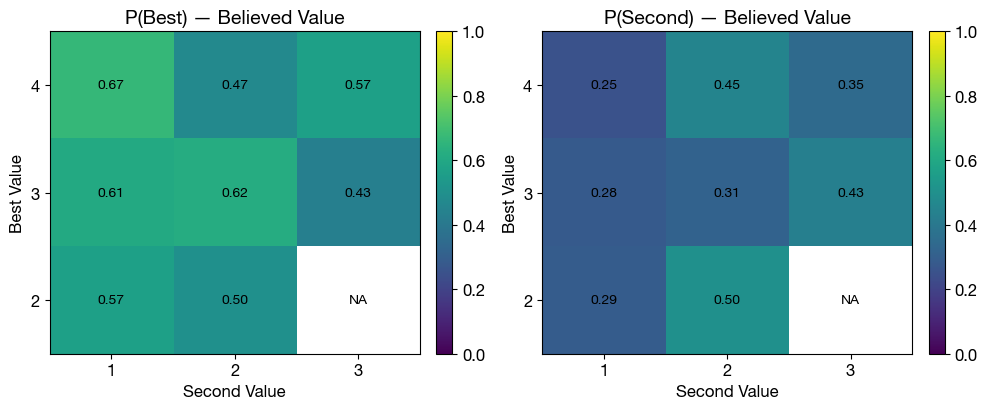

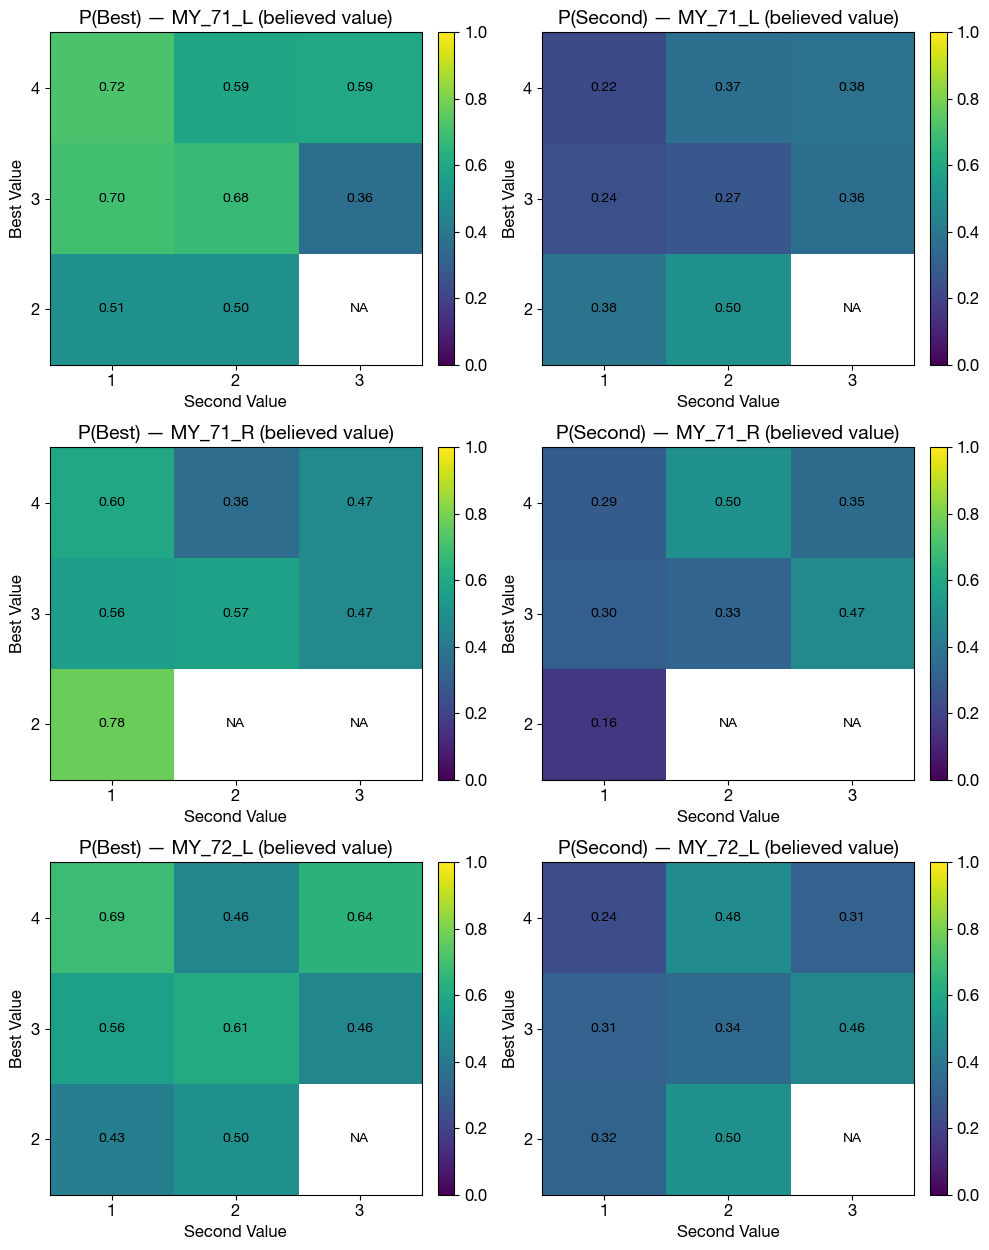

In [6]:
overall_best, overall_second, per_mouse_best, per_mouse_second = \
    accumulate_choice_probs(subject_trials_by_value_problem, use_believed=True)

plot_overall_heatmaps(overall_best, overall_second, annotate=True, use_believed=True)
plot_per_mouse_heatmaps(per_mouse_best, per_mouse_second, annotate=True, use_believed=True)

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/529178932.py:227: RuntimeWarning: Mean of empty slice
  return pd.DataFrame(np.nanmean(stack, axis=0), index=ref.index, columns=ref.columns)


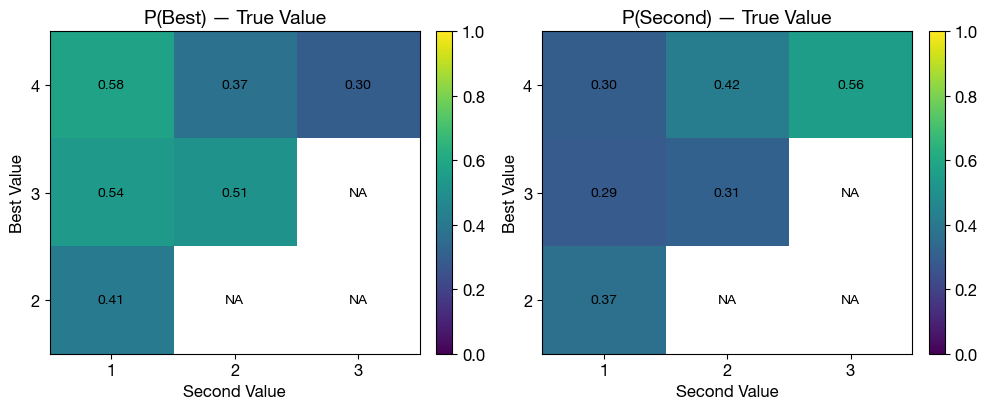

In [7]:
overall_best, overall_second, per_mouse_best, per_mouse_second = \
    accumulate_choice_probs(subject_trials_by_value_problem, use_believed=False)

plot_overall_heatmaps(overall_best, overall_second, annotate=True, use_believed=False)

In [8]:
import numpy as np
import matplotlib.pyplot as plt

BEST_VALS   = [2, 3, 4]
SECOND_VALS = [1, 2, 3]

COLOR_BEST   = "#5DA5DA"
COLOR_SECOND = "#60BD68"

# ---------------------------------------------------------------------------
# Helper: collapse a per-mouse probability DataFrame into psychometric curves
# ---------------------------------------------------------------------------

def _psychometric_data(per_mouse_prob_best, per_mouse_prob_second):
    """
    From per-mouse 3x3 DataFrames, compute p(chosen) as a function of:
      - value of best arm          (averaged over second-best values)
      - value of second-best arm   (averaged over best values)
      - difference (best - second) (averaged over matching cells)

    Returns a dict with keys "best_val", "second_val", "diff", each mapping to:
      {
        "x"      : array of x-axis values,
        "mouse"  : 2-D array (n_mice x n_x) of per-mouse means (NaN where missing),
        "mean"   : 1-D array of grand mean across mice (nanmean),
      }
    for both "best" and "second" choice probabilities.
    """
    mice = sorted(per_mouse_prob_best.keys())

    def collect(per_mouse_prob, x_vals, axis):
        """
        axis=1 -> marginalise over second-best (x = best value)
        axis=0 -> marginalise over best        (x = second value)
        """
        rows = []
        for sid in mice:
            df  = per_mouse_prob[sid].reindex(index=BEST_VALS, columns=SECOND_VALS)
            arr = df.to_numpy(dtype=float)
            row = np.nanmean(arr, axis=axis)
            rows.append(row)
        mat = np.array(rows)
        mean = np.nanmean(mat, axis=0)
        n_valid = np.sum(~np.isnan(mat), axis=0)
        se = np.where(n_valid > 1,
                      np.nanstd(mat, axis=0, ddof=1) / np.sqrt(np.maximum(n_valid, 1)),
                      np.nan)
        return {"x": np.array(x_vals), "mouse": mat, "mean": mean, "se": se}

    def collect_diff(per_mouse_prob):
        """
        x = best_val - second_val, averaged across cells with the same difference.
        """
        diffs = sorted({b - s for b in BEST_VALS for s in SECOND_VALS if b > s})
        rows  = []
        for sid in mice:
            df  = per_mouse_prob[sid].reindex(index=BEST_VALS, columns=SECOND_VALS)
            arr = df.to_numpy(dtype=float)
            row = []
            for d in diffs:
                vals = [arr[bi, si]
                        for bi, b in enumerate(BEST_VALS)
                        for si, s in enumerate(SECOND_VALS)
                        if b - s == d]
                row.append(np.nanmean(vals) if vals else np.nan)
            rows.append(row)
        mat = np.array(rows)
        mean = np.nanmean(mat, axis=0)
        n_valid = np.sum(~np.isnan(mat), axis=0)
        se = np.where(n_valid > 1,
                      np.nanstd(mat, axis=0, ddof=1) / np.sqrt(np.maximum(n_valid, 1)),
                      np.nan)
        return {"x": np.array(diffs), "mouse": mat, "mean": mean, "se": se}

    return {
        "best": {
            "best_val":   collect(per_mouse_prob_best,   BEST_VALS,   axis=1),
            "second_val": collect(per_mouse_prob_best,   SECOND_VALS, axis=0),
            "diff":       collect_diff(per_mouse_prob_best),
        },
        "second": {
            "best_val":   collect(per_mouse_prob_second,   BEST_VALS,   axis=1),
            "second_val": collect(per_mouse_prob_second,   SECOND_VALS, axis=0),
            "diff":       collect_diff(per_mouse_prob_second),
        },
    }


# ---------------------------------------------------------------------------
# Core subplot painter
# ---------------------------------------------------------------------------

def _draw_psychometric(ax, data_best, data_second, xlabel, ylabel, title):
    """
    Draw P(choose best) and P(choose second) on the same axes in different colors.
    Mean values are annotated as text above each best point and below each second point.

    data_best, data_second : {"x": array, "mouse": (n_mice, n_x) array, "mean": (n_x,) array}
    """
    for data, color, label, text_offset, va in [
        (data_best,   COLOR_BEST,   "P(best)",   0.05, "bottom"),
        (data_second, COLOR_SECOND, "P(second)", -0.05, "top"),
    ]:
        x    = data["x"]
        mat  = data["mouse"]
        mean = data["mean"]

        for i in range(mat.shape[0]):
            y    = mat[i]
            mask = ~np.isnan(y)
            if mask.sum() >= 2:
                ax.plot(x[mask], y[mask], color=color, lw=1, alpha=0.3)
            elif mask.sum() == 1:
                ax.plot(x[mask], y[mask], "o", color=color, ms=3, alpha=0.3)

        se   = data["se"]
        mask = ~np.isnan(mean)
        if mask.sum() >= 2:
            ax.fill_between(x[mask], mean[mask] - se[mask], mean[mask] + se[mask],
                            color=color, alpha=0.15, zorder=3)
            ax.plot(x[mask], mean[mask], color=color, lw=2.2, label=label, zorder=5)
            ax.plot(x[mask], mean[mask], "o", color=color, ms=5, zorder=6)
        elif mask.sum() == 1:
            ax.plot(x[mask], mean[mask], "o", color=color, ms=6, label=label, zorder=6)

        # annotate mean value above (best) or below (second) each point
        for xi, mi in zip(x[mask], mean[mask]):
            ax.text(xi, mi + text_offset, f"{mi:.2f}",
                    ha="center", va=va, fontsize=10, color=color)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.set_ylim(0, 1)
    ax.set_xticks(data_best["x"])
    ax.legend(fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

def plot_psychometric_curves(per_mouse_best_prob, per_mouse_second_prob,
                              use_believed=False):
    """
    Produce a single figure with three subplots, each showing P(choose best)
    and P(choose second best) together in different colors:

      subplot 1: vs. value of best arm
      subplot 2: vs. value of second-best arm
      subplot 3: vs. difference (best - second)

    Individual mice are thin lines; the cross-mouse mean is a thick line.

    Parameters
    ----------
    per_mouse_best_prob   : dict[subject_id -> 3x3 DataFrame]
    per_mouse_second_prob : dict[subject_id -> 3x3 DataFrame]
    use_believed          : bool  — used only for figure title labelling
    """
    label = "Believed Value" if use_believed else "True Value"
    data  = _psychometric_data(per_mouse_best_prob, per_mouse_second_prob)

    x_labels = {
        "best_val":   "Value of Best",
        "second_val": "Value of Second",
        "diff":       "Value of Best - Second",
    }
    keys = ["best_val", "second_val", "diff"]

    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    fig.suptitle(f"Psychometric Curves ({label})", fontsize=16, fontweight="bold")

    for ax, key in zip(axs, keys):
        _draw_psychometric(
            ax,
            data["best"][key],
            data["second"][key],
            xlabel=x_labels[key],
            ylabel="Choice Probability",
            title=x_labels[key],
        )

    plt.tight_layout()
    plt.show()

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/529178932.py:227: RuntimeWarning: Mean of empty slice
  return pd.DataFrame(np.nanmean(stack, axis=0), index=ref.index, columns=ref.columns)
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/529178932.py:227: RuntimeWarning: Mean of empty slice
  return pd.DataFrame(np.nanmean(stack, axis=0), index=ref.index, columns=ref.columns)


    Trials: 5 total | 0 included | 5 excluded (100.0%) — unseen arms
    Trials: 44 total | 3 included | 41 excluded (93.2%) — unseen arms
    Trials: 56 total | 36 included | 20 excluded (35.7%) — unseen arms
    Trials: 64 total | 31 included | 33 excluded (51.6%) — unseen arms
    Trials: 48 total | 40 included | 8 excluded (16.7%) — unseen arms
    Trials: 38 total | 19 included | 19 excluded (50.0%) — unseen arms
    Trials: 77 total | 66 included | 11 excluded (14.3%) — unseen arms
    Trials: 120 total | 104 included | 16 excluded (13.3%) — unseen arms
    Trials: 170 total | 166 included | 4 excluded (2.4%) — unseen arms
    Trials: 109 total | 105 included | 4 excluded (3.7%) — unseen arms
    Trials: 64 total | 33 included | 31 excluded (48.4%) — unseen arms
    Trials: 32 total | 5 included | 27 excluded (84.4%) — unseen arms
    Trials: 88 total | 71 included | 17 excluded (19.3%) — unseen arms
    Trials: 48 total | 39 included | 9 excluded (18.8%) — unseen arms
    Trials

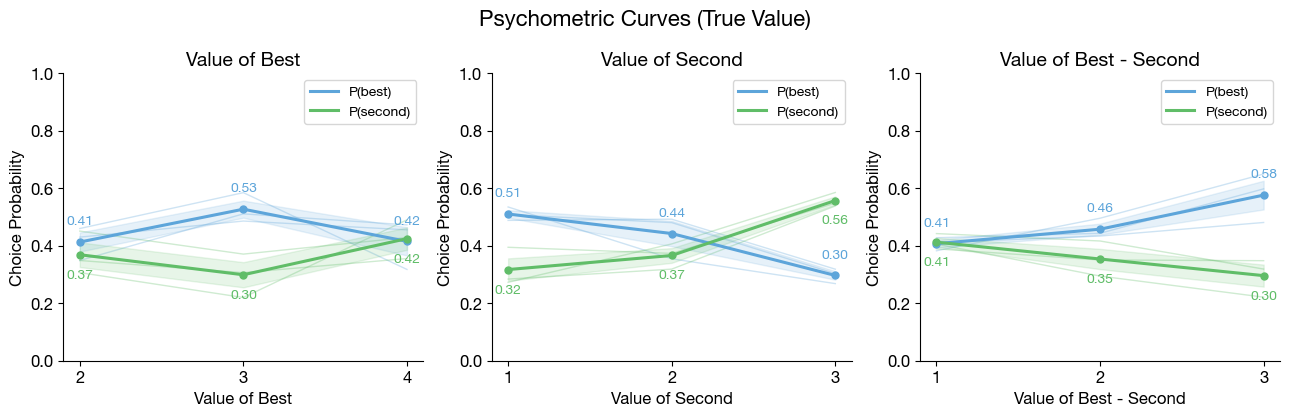

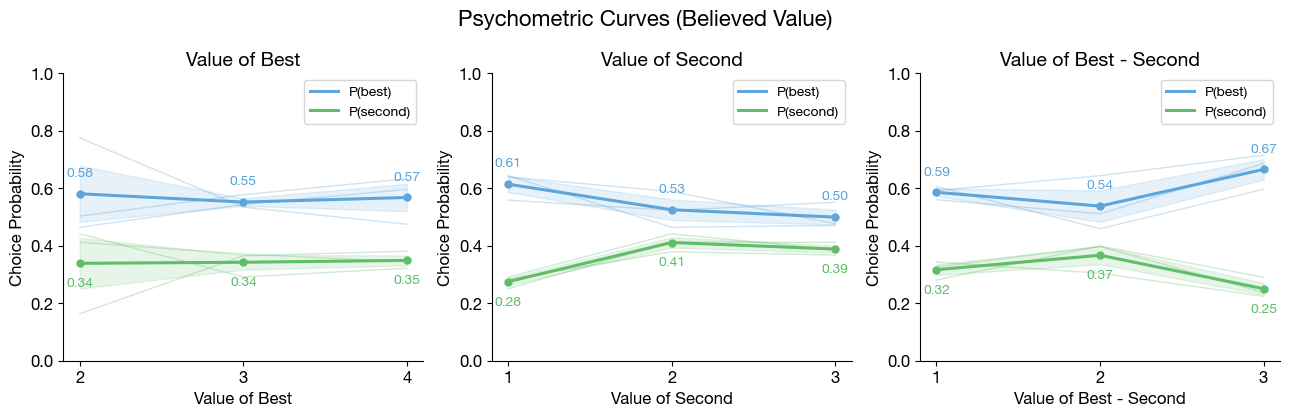

In [9]:
true_best, true_second, per_mouse_true_best, per_mouse_true_second = accumulate_choice_probs(subject_trials_by_value_problem, use_believed=False)
believed_best, believed_second, per_mouse_believed_best, per_mouse_believed_second = accumulate_choice_probs(subject_trials_by_value_problem, use_believed=True)

plot_psychometric_curves(per_mouse_true_best, per_mouse_true_second, use_believed=False)
plot_psychometric_curves(per_mouse_believed_best, per_mouse_believed_second, use_believed=True)

Problem 13


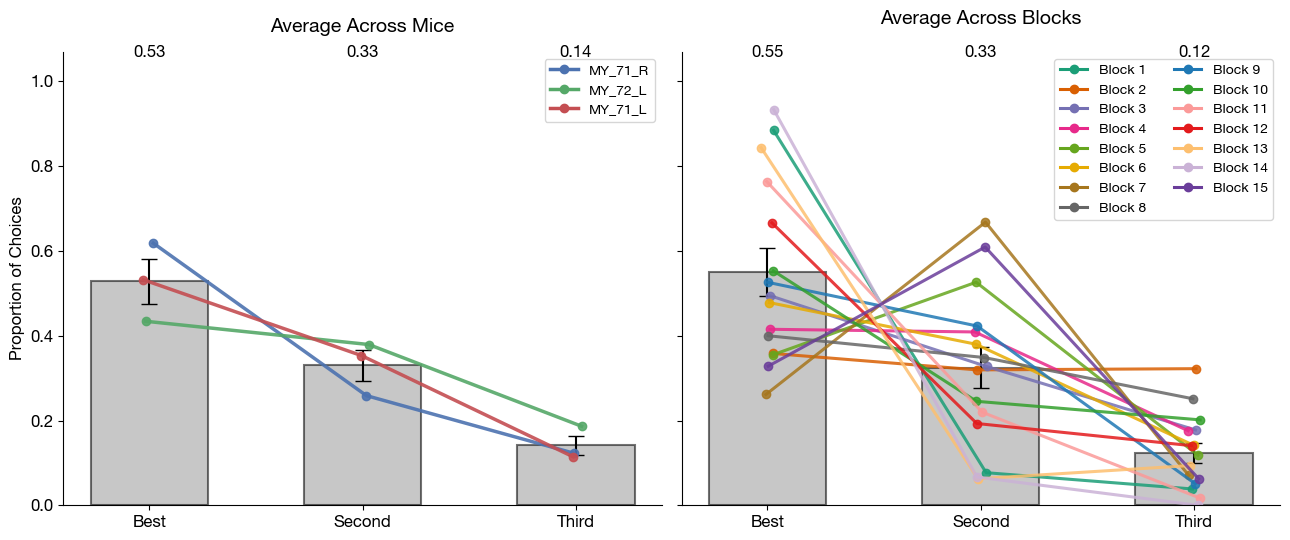

Problem 14


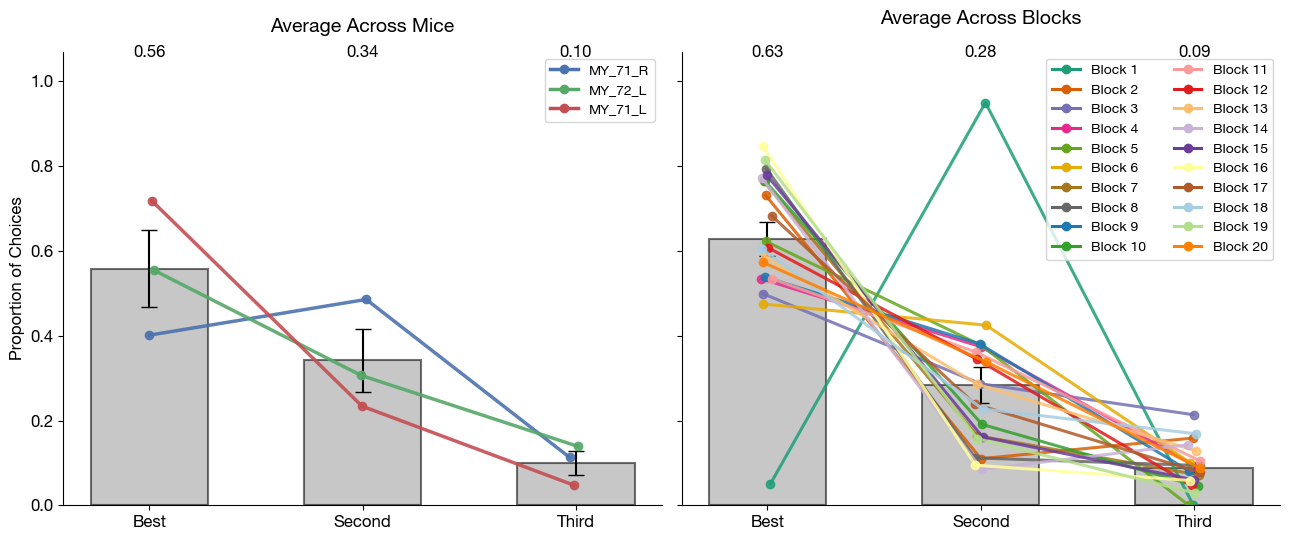

Problem 15


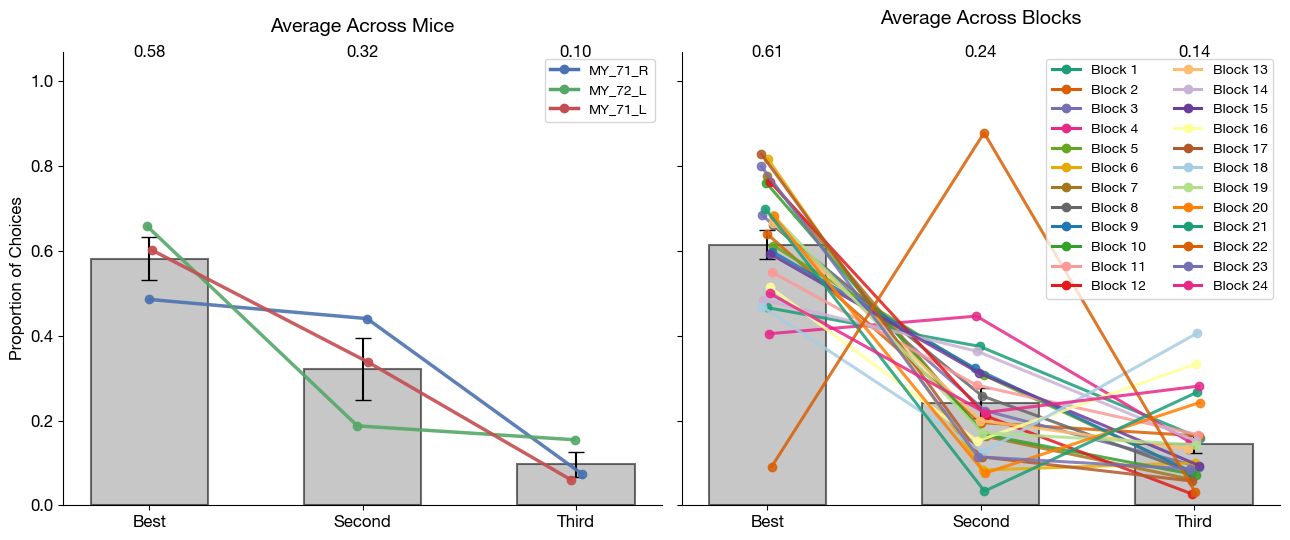

Problem 16


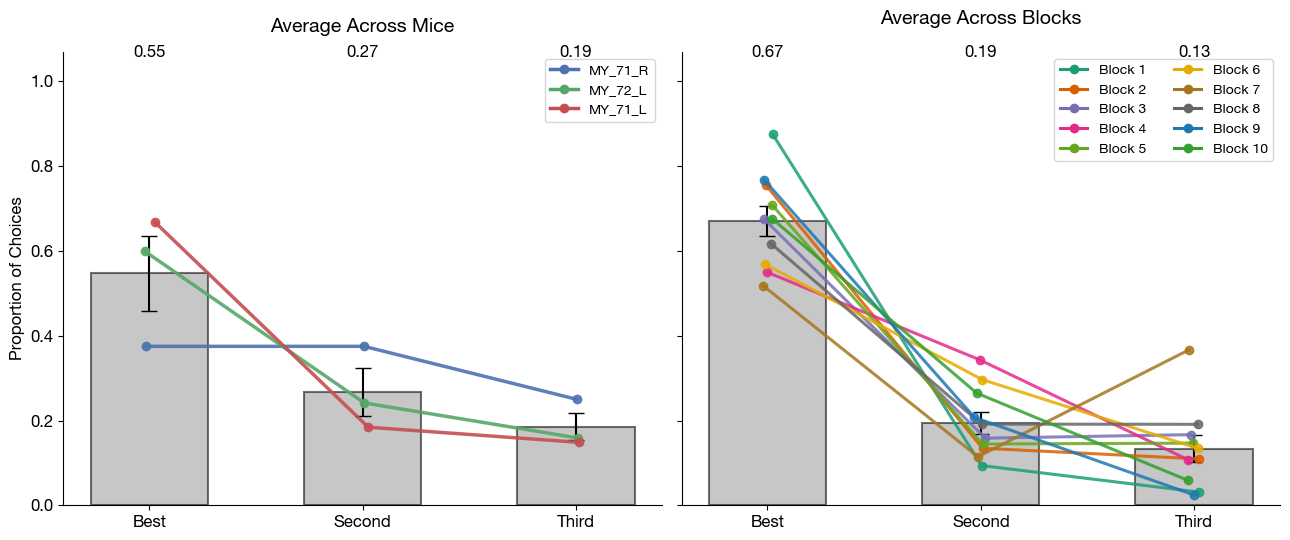

Problem 17


/Users/megyoung/magnitude-bandit-analysis/src/behavior_visualization/plot_rank_proportions.py:101: RuntimeWarning: Mean of empty slice
  "best": np.nanmean([r.get("best_prop", np.nan) for r in rows]),
/Users/megyoung/magnitude-bandit-analysis/src/behavior_visualization/plot_rank_proportions.py:102: RuntimeWarning: Mean of empty slice
  "second": np.nanmean([r.get("second_prop", np.nan) for r in rows]),
/Users/megyoung/magnitude-bandit-analysis/src/behavior_visualization/plot_rank_proportions.py:103: RuntimeWarning: Mean of empty slice
  "third": np.nanmean([r.get("third_prop", np.nan) for r in rows]),


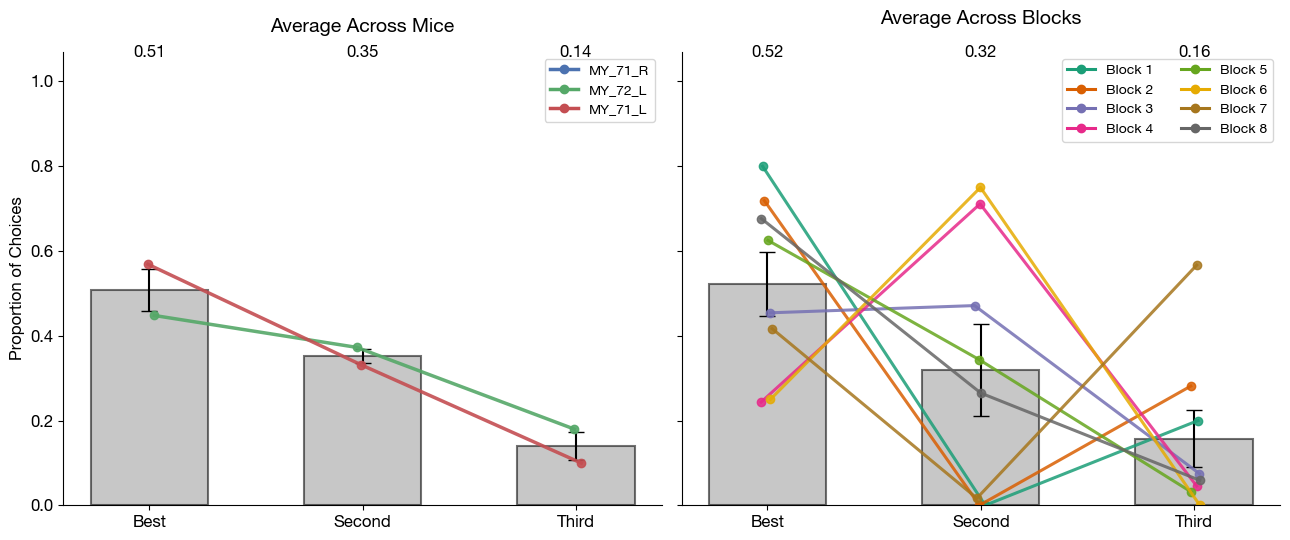

In [9]:
# ---------------------------------------------------------------------------
# Rank proportion analysis — true values AND believed values
# ---------------------------------------------------------------------------

import numpy as np


def get_rank_counts_by_good_reversal(good_reversal_info, include_first_block=True):
    """Count best/second/third arm choices in each reversal's post window (true ranks)."""
    rank_counts = {}
    for subj in good_reversal_info:
        rank_counts[subj] = []
        for rev in good_reversal_info[subj]:
            num_best   = sum(rev['choices_by_rank']['best']['post'])
            num_second = sum(rev['choices_by_rank']['second']['post'])
            num_third  = sum(rev['choices_by_rank']['third']['post'])
            total = num_best + num_second + num_third
            rank_counts[subj].append({
                'best':        num_best,
                'second':      num_second,
                'third':       num_third,
                'total':       total,
                'best_prop':   num_best   / total if total > 0 else np.nan,
                'second_prop': num_second / total if total > 0 else np.nan,
                'third_prop':  num_third  / total if total > 0 else np.nan,
            })
    return rank_counts


def _compute_believed_ranks_continuous(choices, reward_magnitudes):
    """Compute believed rank of chosen arm at every trial, carrying last-seen values
    continuously across the session. Returns None for trials where any arm is unseen."""
    last_seen = {}
    results   = []
    n_excluded = 0
    n_included = 0

    for i, rm in enumerate(reward_magnitudes):
        choice   = choices[i]
        all_arms = list(rm.keys())
        believed = {arm: last_seen[arm] for arm in all_arms if arm in last_seen}

        if len(believed) < len(all_arms):
            results.append(None)
            n_excluded += 1
        else:
            ranked = sorted(believed.items(), key=lambda x: (-x[1], str(x[0])))
            best_mag   = ranked[0][1] if len(ranked) >= 1 else None
            second_mag = ranked[1][1] if len(ranked) >= 2 else None
            tied = (best_mag is not None and second_mag is not None
                    and best_mag == second_mag)
            chosen_rank = None
            for rank_idx, (arm, _) in enumerate(ranked):
                if arm == choice:
                    chosen_rank = ["best", "second", "third"][min(rank_idx, 2)]
                    break
            results.append({"chosen_rank": chosen_rank, "tied": tied})
            n_included += 1

        if choice and choice in rm:
            last_seen[choice] = rm[choice]

    total = n_included + n_excluded
    pct   = 100 * n_excluded / total if total > 0 else 0
    return results

def get_believed_rank_counts_by_good_reversal(good_reversal_info, subjects_trials):
    """Count best/second/third believed-rank choices in each reversal's post window.

    Believed values are carried over continuously across reversals (last-seen magnitudes).
    Trials where any arm has never been visited are excluded.
    Tied believed values are split evenly (0.5 to each tied rank).

    Parameters
    ----------
    good_reversal_info : dict[subject -> list[reversal_dict]]
        Output of get_good_reversal_info(), with trial_window_idx["post"] giving
        absolute trial indices into the merged session.
    subjects_trials : dict[subject -> dict[session_id -> session_data]]
        Same structure passed to get_good_reversal_info().
    """
    from src.behavior_analysis.get_variables_across_sessions import get_vars_across_all_sessions

    merged, _ = get_vars_across_all_sessions(subjects_trials)
    result    = {}

    for subj, reversals in good_reversal_info.items():
        result[subj] = []
        d = merged.get(subj, {})

        # build reward_magnitudes list from reward_magnitudes_by_tower if needed
        rbt = d.get("reward_magnitudes_by_tower", {})
        choices_merged = d.get("choices_by_tower", {})

        # reconstruct choices as a list from choices_by_tower (one-hot)
        towers = list(rbt.keys())
        if not towers:
            result[subj] = [None] * len(reversals)
            continue

        n = max(len(v) for v in rbt.values())
        reward_magnitudes = [{t: rbt[t][i] for t in towers} for i in range(n)]

        # rebuild choice sequence from choices_by_tower one-hots
        choices = [None] * n
        cbt = d.get("choices_by_tower", {})
        for t, arr in cbt.items():
            for i, v in enumerate(arr):
                if v == 1 and i < n:
                    choices[i] = t

        believed = _compute_believed_ranks_continuous(choices, reward_magnitudes)

        for rev in reversals:
            post_idx   = rev.get("trial_window_idx", {}).get("post", [])
            num_best   = 0.0
            num_second = 0.0
            num_third  = 0.0
            total      = 0

            for i in post_idx:
                if i >= len(believed) or believed[i] is None:
                    continue
                b = believed[i]
                total += 1
                if b["tied"]:
                    if b["chosen_rank"] in ("best", "second"):
                        num_best   += 0.5
                        num_second += 0.5
                    else:
                        num_third  += 1.0
                else:
                    if b["chosen_rank"] == "best":
                        num_best   += 1.0
                    elif b["chosen_rank"] == "second":
                        num_second += 1.0
                    elif b["chosen_rank"] == "third":
                        num_third  += 1.0

            result[subj].append({
                'best':        num_best,
                'second':      num_second,
                'third':       num_third,
                'total':       total,
                'best_prop':   num_best   / total if total > 0 else np.nan,
                'second_prop': num_second / total if total > 0 else np.nan,
                'third_prop':  num_third  / total if total > 0 else np.nan,
            })

    return result


# ---------------------------------------------------------------------------
# Per-problem rank proportion plots — true and believed
# ---------------------------------------------------------------------------
from src.behavior_visualization.plot_rank_proportions import *

CUTOFF_PROBLEM = 13  # only analyse problems >= this number
CUTOFF_PROBLEM_HIGH = 17 # only analyse problems <= this number

for problem_number, subjects_trials in subjects_trials_by_problem.items():
    if problem_number < CUTOFF_PROBLEM or problem_number > CUTOFF_PROBLEM_HIGH:
        continue

    print(f"Problem {problem_number}")
    problem = f"problem-{problem_number:02d}"

    reversal_windows = get_good_reversal_info(subjects_trials, include_first_block=True)

    # --- Believed rank proportions ---
    rank_counts_believed = get_believed_rank_counts_by_good_reversal(reversal_windows, subjects_trials)
    plot_rank_proportions(rank_counts_believed, average_across_mice_pvalues=None, save_path=None, by_mouse=False, by_block=False, average=True)

Subjects: 6
Total reversals: 1051

Believed rank proportions — pooled across problems >= CUTOFF_PROBLEM:
  best_vs_second: p = 0.0001
  best_vs_third: p = 0.0000
  second_vs_third: p = 0.0000


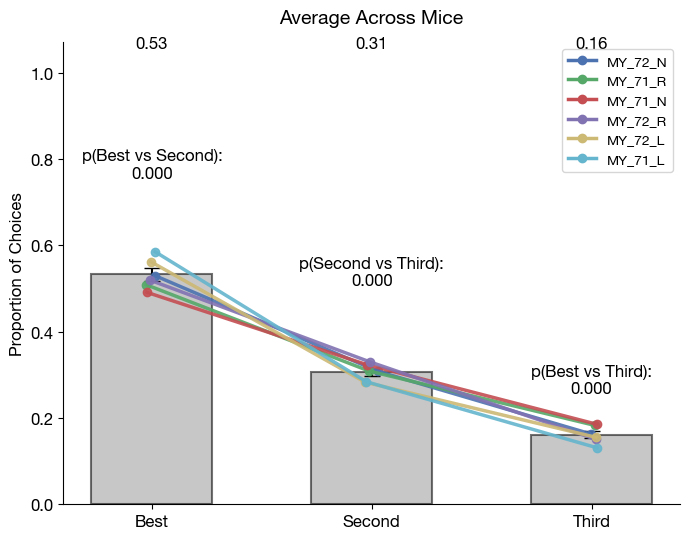

In [10]:
# ---------------------------------------------------------------------------
# Aggregate believed rank proportions across all problems >= CUTOFF_PROBLEM
# and run paired t-tests: best vs second, best vs third, second vs third
# ---------------------------------------------------------------------------
import src.behavior_visualization.plot_style  # noqa: F401 — applies rcParams
from src.behavior_visualization.plot_problem_summary import (
    plot_rank_proportions_average_without_blocks,
)
from src.behavior_analysis.get_diagnostic_p_value import *
from src.behavior_analysis.merge_across_problems import *

# --- Collect reversal windows per problem (reuse windows_by_problem from above) ---
# Compute believed rank counts per problem separately, then pool per subject.
# This avoids merging sessions across problems (which have different tower sets
# and would produce arrays of unequal length).
all_believed_rank_counts = {}

for p in sorted(subjects_trials_by_problem.keys()):
    # if p < CUTOFF_PROBLEM or p > CUTOFF_PROBLEM_HIGH:
        # continue
    subjects_trials = subjects_trials_by_problem[p]
    reversal_windows = get_good_reversal_info(subjects_trials, include_first_block=True)

    believed_rank_counts = get_believed_rank_counts_by_good_reversal(
        reversal_windows, subjects_trials  # single-problem — towers are consistent
    )

    for subj, rows in believed_rank_counts.items():
        all_believed_rank_counts.setdefault(subj, []).extend(rows)

print("Subjects:", len(all_believed_rank_counts))
print("Total reversals:", sum(len(v) for v in all_believed_rank_counts.values()))

# --- P-values across subjects (pooled across problems) ---
p_values_believed = pvalue_paired_t_best_vs_second_vs_third(all_believed_rank_counts)
print("\nBelieved rank proportions — pooled across problems >= CUTOFF_PROBLEM:")
for k, v in p_values_believed.items():
    print(f"  {k}: p = {v:.4f}")

# --- Plot pooled believed rank proportions with p-values ---
plot_rank_proportions_average_without_blocks(
    all_believed_rank_counts,
    average_across_mice_pvalues=p_values_believed,
    save_path=None,
)

In [ ]:
import pandas as pd
import numpy as np

rows = []

for mouse, windows in all_believed_rank_counts.items():

    # Remove empty reversal windows
    windows = [w for w in windows if w["total"] > 0]

    rows.append({
        "Mouse": mouse,
        "Best": np.mean([w["best_prop"] for w in windows]),
        "Second": np.mean([w["second_prop"] for w in windows]),
        "Third": np.mean([w["third_prop"] for w in windows]),
    })

df = (
    pd.DataFrame(rows)
      .sort_values("Mouse")
      .reset_index(drop=True)
)

print(df)

# df.to_csv("believed_rank_proportions_by_mouse.csv", index=False)

     Mouse      Best    Second     Third
0  MY_71_L  0.585067  0.284077  0.130856
1  MY_71_N  0.491086  0.323481  0.185433
2  MY_71_R  0.508566  0.308852  0.182582
3  MY_72_L  0.561961  0.282928  0.155111
4  MY_72_N  0.529525  0.307963  0.162512
5  MY_72_R  0.519640  0.330014  0.150346


Subjects: 3
Total reversals: 126

 True rank proportions — pooled across problems >= CUTOFF_PROBLEM:
  best_vs_second: p = 0.1008
  best_vs_third: p = 0.0088
  second_vs_third: p = 0.1331


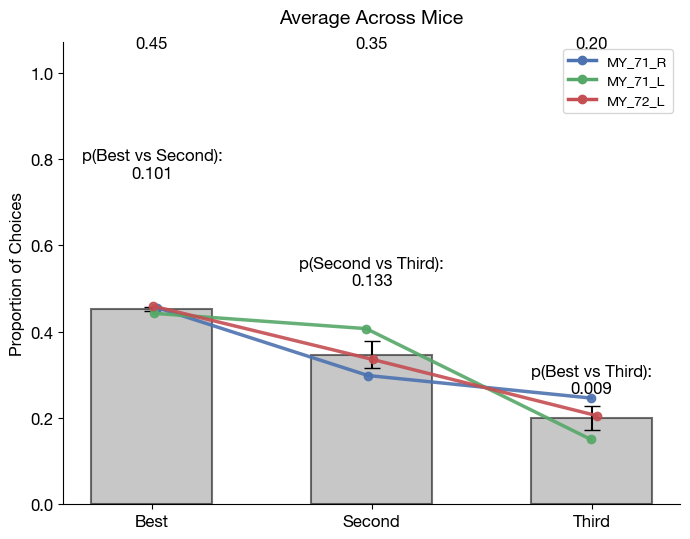

In [12]:
# ---------------------------------------------------------------------------
# Aggregate believed rank proportions across all problems >= CUTOFF_PROBLEM
# and run paired t-tests: best vs second, best vs third, second vs third
# ---------------------------------------------------------------------------
import src.behavior_visualization.plot_style  # noqa: F401 — applies rcParams
from src.behavior_visualization.plot_problem_summary import (
    plot_rank_proportions_average_without_blocks,
)
from src.behavior_analysis.get_diagnostic_p_value import *
from src.behavior_analysis.merge_across_problems import *

# --- Collect reversal windows per problem (reuse windows_by_problem from above) ---
# Compute believed rank counts per problem separately, then pool per subject.
# This avoids merging sessions across problems (which have different tower sets
# and would produce arrays of unequal length).
all_rank_counts = {}

for p in sorted(subjects_trials_by_problem.keys()):
    if p < CUTOFF_PROBLEM or p > CUTOFF_PROBLEM_HIGH:
        continue
    subjects_trials = subjects_trials_by_problem[p]
    reversal_windows = get_good_reversal_info(subjects_trials, include_first_block=True)

    rank_counts = get_rank_counts_by_good_reversal(
        reversal_windows, subjects_trials  # single-problem — towers are consistent
    )

    for subj, rows in rank_counts.items():
        all_rank_counts.setdefault(subj, []).extend(rows)

print("Subjects:", len(all_rank_counts))
print("Total reversals:", sum(len(v) for v in all_rank_counts.values()))

# --- P-values across subjects (pooled across problems) ---
p_values = pvalue_paired_t_best_vs_second_vs_third(all_rank_counts)
print("\n True rank proportions — pooled across problems >= CUTOFF_PROBLEM:")
for k, v in p_values.items():
    print(f"  {k}: p = {v:.4f}")

# --- Plot pooled true rank proportions with p-values ---
plot_rank_proportions_average_without_blocks(
    all_rank_counts,
    average_across_mice_pvalues=p_values,
    save_path=None,
)

In [13]:
"""
reversal_analysis.py
====================
Reversal-aligned choice probability analysis with:
  - Secondary y-axis showing mean rank-1/2/3 magnitudes across reversals
  - Toggle for reversal type: "all", "best_to_third", "second_to_third"
  - Moving-average smoothing
  - Per-subject and across-subject aggregation

Public API
----------
    classify_reversal_type(reversal)
    filter_reversals_by_type(reversal_windows, reversal_type)
    get_choice_probs_around_good_reversals_prev_ranks(reversal_windows, pre, post, skip_n_trials_after_reversal)
    apply_moving_average(x, per_subject, window, mode, split_at)
    plot_reversal_choice_probs(x, per_subject, across, reversal_windows, reversal_type, use_moving_avg, ...)
"""

import warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ---------------------------------------------------------------------------
# Style
# ---------------------------------------------------------------------------
mpl.rcParams["font.family"]      = "sans-serif"
mpl.rcParams["font.sans-serif"]  = ["Helvetica Neue", "Helvetica", "Arial"]
mpl.rcParams["xtick.labelsize"]  = 12
mpl.rcParams["ytick.labelsize"]  = 12
mpl.rcParams["axes.labelsize"]   = 12
mpl.rcParams["axes.titlesize"]   = 14

COLOR_MAP = {
    "prev_best":  "#5DA5DA",
    "prev_sec":   "#60BD68",
    "prev_third": "#7f7f7f",
}
LABEL_MAP = {
    "prev_best":  "Prev Best",
    "prev_sec":   "Prev Second",
    "prev_third": "Prev Third",
}
VALUE_COLOR_MAP = {
    "rank1": "#335A79",
    "rank2": "#39703D",
    "rank3": "#282828",
}
VALUE_LABEL_MAP = {
    "rank1": "Prev Best Value",
    "rank2": "Prev Second Value",
    "rank3": "Prev Third Value",
}
PLOT_KEYS = ["prev_best", "prev_sec", "prev_third"]


# ---------------------------------------------------------------------------
# Reversal classification
# ---------------------------------------------------------------------------

def classify_reversal_type(reversal):
    """
    Determine whether a reversal is "best_to_third" or "second_to_third" by
    comparing rank orderings before and after the reversal.

    A reversal is "best_to_third"   if the pre-reversal best arm becomes third
    A reversal is "second_to_third" if the pre-reversal second arm becomes third
    Returns "other" if neither condition holds.

    Parameters
    ----------
    reversal : dict with keys:
        "reward_magnitudes_by_tower_before" : dict[tower -> magnitude]
        "reward_magnitudes_by_tower_after"  : dict[tower -> magnitude]

    Returns
    -------
    str : "best_to_third", "second_to_third", or "other"
    """
    before = reversal["reward_magnitudes_by_tower_before"]
    after  = reversal["reward_magnitudes_by_tower_after"]

    def rank_order(d):
        return [arm for arm, _ in sorted(d.items(), key=lambda kv: (-kv[1], str(kv[0])))]

    ranked_before = rank_order(before)
    ranked_after  = rank_order(after)

    if len(ranked_before) < 3 or len(ranked_after) < 3:
        return "other"

    prev_best  = ranked_before[0]
    prev_sec   = ranked_before[1]
    post_third = ranked_after[2]

    if prev_best == post_third:
        return "best_to_third"
    if prev_sec == post_third:
        return "second_to_third"
    return "other"


def filter_reversals_by_type(reversal_windows, reversal_type="all"):
    """
    Filter reversal_windows to only include reversals of the specified type.

    Parameters
    ----------
    reversal_windows : dict[subject_id -> list[reversal_dict]]
    reversal_type    : "all", "best_to_third", or "second_to_third"

    Returns
    -------
    dict[subject_id -> list[reversal_dict]]
    """
    if reversal_type == "all":
        return reversal_windows

    filtered = {}
    for subj, revs in reversal_windows.items():
        kept = [r for r in revs if classify_reversal_type(r) == reversal_type]
        if kept:
            filtered[subj] = kept
    return filtered


# ---------------------------------------------------------------------------
# Rank classification helper (unchanged from original)
# ---------------------------------------------------------------------------

def _classify_prev_ranks(reversal):
    before  = reversal["reward_magnitudes_by_tower_before"]
    ranked  = sorted(before.items(), key=lambda kv: (-kv[1], str(kv[0])))
    if len(ranked) < 3:
        raise ValueError(f"Need at least 3 towers; got {len(ranked)}")
    return ranked[0][0], ranked[1][0], ranked[2][0]   # prev_best, prev_sec, prev_third


# ---------------------------------------------------------------------------
# Magnitude extraction for secondary axis
# ---------------------------------------------------------------------------

def _compute_rank_magnitudes_over_time(reversal_windows, x):
    """
    For each trial offset in x, compute the mean ± SE of the magnitudes of the
    prev_best and prev_sec arms (identified by arm identity, not current rank),
    across all reversals and subjects.

    This tracks the specific arms that were best/second BEFORE the reversal,
    so the traces show one arm dropping and one rising at the reversal boundary,
    making them interpretable as "prev best arm value" and "prev second arm value".

    Returns
    -------
    dict with keys "rank1" (prev best arm) and "rank2" (prev second arm), each:
        {"mean": array, "se": array}  both shape (len(x),)
    """
    x     = np.asarray(x, dtype=float)
    accum = {"rank1": [], "rank2": [], "rank3": []}

    for subj, revs in reversal_windows.items():
        for r in revs:
            before = r["reward_magnitudes_by_tower_before"]
            after  = r.get("reward_magnitudes_by_tower_after", {})
            ranked_before = sorted(before.items(), key=lambda kv: (-kv[1], str(kv[0])))
            if len(ranked_before) < 3:
                continue
            prev_best_arm  = ranked_before[0][0]
            prev_sec_arm   = ranked_before[1][0]
            prev_third_arm = ranked_before[2][0]

            # Use per-trial magnitude data if available (from enrich_reversal_windows)
            # otherwise fall back to static before/after values
            per_trial = r.get("reward_magnitudes_by_tower_over_time")

            T   = len(x)
            row = {"rank1": np.full(T, np.nan), "rank2": np.full(T, np.nan), "rank3": np.full(T, np.nan)}

            arm_traces = r.get("reward_magnitudes_by_tower_over_time")
            if arm_traces is not None:
                # Use trial-by-trial magnitude of the specific prev_best/prev_sec/prev_third arms
                pb_trace = arm_traces.get(prev_best_arm,  np.full(T, np.nan))
                ps_trace = arm_traces.get(prev_sec_arm,   np.full(T, np.nan))
                pt_trace = arm_traces.get(prev_third_arm, np.full(T, np.nan))
                n_trace  = min(len(pb_trace), len(ps_trace), len(pt_trace), T)
                row["rank1"][:n_trace] = pb_trace[:n_trace]
                row["rank2"][:n_trace] = ps_trace[:n_trace]
                row["rank3"][:n_trace] = pt_trace[:n_trace]
            else:
                # static fallback: use before magnitudes for t<0, after for t>=0
                for ti, t in enumerate(x):
                    src = before if t < 0 else (after or before)
                    row["rank1"][ti] = src.get(prev_best_arm,  np.nan)
                    row["rank2"][ti] = src.get(prev_sec_arm,   np.nan)
                    row["rank3"][ti] = src.get(prev_third_arm, np.nan)

            accum["rank1"].append(row["rank1"])
            accum["rank2"].append(row["rank2"])
            accum["rank3"].append(row["rank3"])

    result = {}
    for key in ("rank1", "rank2", "rank3"):
        if accum[key]:
            mat         = np.vstack(accum[key])
            n           = mat.shape[0]
            mean        = np.nanmean(mat, axis=0)
            se          = (np.nanstd(mat, axis=0, ddof=1) / np.sqrt(n)
                           if n > 1 else np.zeros(len(x)))
            result[key] = {"mean": mean, "se": se}
        else:
            nan         = np.full(len(x), np.nan)
            result[key] = {"mean": nan, "se": nan}
    return result


def enrich_reversal_windows_with_magnitudes(reversal_windows, subjects_trials, pre, post):
    """
    Adds "reward_magnitudes_by_rank_over_time" to each reversal dict — the true
    per-trial rank-1 and rank-2 magnitudes aligned to the pre/post window.

    Call this after get_good_reversal_info() and pass the enriched windows to
    plot_reversal_choice_probs(). Existing keys are untouched so other code
    using the original reversal_windows is unaffected.

    Parameters
    ----------
    reversal_windows : dict[subject_id -> list[reversal_dict]]
        Output of get_good_reversal_info().
    subjects_trials  : dict[subject_id -> dict[session_id -> session_data]]
        Raw session data (same as passed to get_good_reversal_info).
    pre, post        : int — must match values used in get_good_reversal_info()

    Returns
    -------
    reversal_windows : same dict, mutated in-place and returned for convenience
    """
    from src.behavior_analysis.get_variables_across_sessions import get_vars_across_all_sessions

    for subj, revs in reversal_windows.items():
        if not revs:
            continue

        subj_data       = subjects_trials.get(subj, {})
        merged, _       = get_vars_across_all_sessions({subj: subj_data})
        reward_by_tower = merged.get(subj, {}).get("reward_magnitudes_by_tower", {})

        if not reward_by_tower:
            continue

        towers   = list(reward_by_tower.keys())
        n_trials = max(len(v) for v in reward_by_tower.values())

        for r in revs:
            pre_idx  = r["trial_window_idx"]["pre"]
            post_idx = r["trial_window_idx"]["post"]
            all_idx  = pre_idx + post_idx
            T        = len(all_idx)

            rank1 = np.full(T, np.nan)
            rank2 = np.full(T, np.nan)

            for pos, trial_i in enumerate(all_idx):
                if trial_i >= n_trials:
                    continue
                mags = sorted(
                    (reward_by_tower[t][trial_i] for t in towers
                     if trial_i < len(reward_by_tower[t])),
                    reverse=True
                )
                if len(mags) >= 1: rank1[pos] = mags[0]
                if len(mags) >= 2: rank2[pos] = mags[1]

            # Pad to the full expected window length (pre + post) so all
            # reversals have the same length array for vstack
            T_full = pre + post
            rank1_padded = np.full(T_full, np.nan)
            rank2_padded = np.full(T_full, np.nan)
            rank1_padded[:T] = rank1
            rank2_padded[:T] = rank2

            r["reward_magnitudes_by_rank_over_time"] = {
                "rank1": rank1_padded,
                "rank2": rank2_padded,
            }

            # Also store per-arm magnitude traces so plotting can track
            # specific arm identities (prev_best, prev_sec) across the window
            arm_traces = {}
            for t in towers:
                trace = np.full(T_full, np.nan)
                for pos, trial_i in enumerate(all_idx):
                    if trial_i < len(reward_by_tower.get(t, [])):
                        if pos < T_full:
                            trace[pos] = reward_by_tower[t][trial_i]
                arm_traces[t] = trace
            r["reward_magnitudes_by_tower_over_time"] = arm_traces

    return reversal_windows


# ---------------------------------------------------------------------------
# Core aggregation
# ---------------------------------------------------------------------------

def get_choice_probs_around_good_reversals_prev_ranks(
    reversal_windows, pre=10, post=40, skip_n_trials_after_reversal=0
):
    """
    Aggregate reversal-aligned choice probabilities for arms classified by their
    pre-reversal rank (prev_best, prev_sec, prev_third).

    Parameters
    ----------
    reversal_windows              : dict[subject_id -> list[reversal_dict]]
    pre                           : int, trials before reversal
    post                          : int, trials after reversal
    skip_n_trials_after_reversal  : int, trials to drop immediately post-reversal
                                    (trial 0 / anchor is always kept)

    Returns
    -------
    x            : array of trial offsets
    per_subject  : dict[subject_id -> dict with matrices and means]
    across       : dict with cross-subject mean, se, counts
    """
    if skip_n_trials_after_reversal < 0:
        raise ValueError("skip_n_trials_after_reversal must be >= 0")
    if skip_n_trials_after_reversal >= post:
        raise ValueError("skip_n_trials_after_reversal must be < post")

    def keep_zero_then_skip(seq, skip):
        return seq if skip <= 0 else seq[:1] + seq[skip:]

    T = pre + (post - skip_n_trials_after_reversal)
    x = np.concatenate([np.arange(-pre, 0), np.arange(0, post - skip_n_trials_after_reversal)])

    per_subject = {}

    for subj, revs in reversal_windows.items():
        if not revs:
            continue

        mats = {"prev_best": [], "prev_sec": [], "prev_third": []}

        for r in revs:
            pb, ps, pt = _classify_prev_ranks(r)

            def extract(arm):
                pre_seq  = r["choices_by_tower"][arm]["pre"]
                post_seq = keep_zero_then_skip(r["choices_by_tower"][arm]["post"],
                                               skip_n_trials_after_reversal)
                raw = pre_seq + post_seq
                out = np.full(T, np.nan, dtype=float)
                n   = min(len(raw), T)
                out[:n] = raw[:n]
                return out

            mats["prev_best"].append(extract(pb))
            mats["prev_sec"].append(extract(ps))
            mats["prev_third"].append(extract(pt))

        if not mats["prev_best"]:
            continue

        stacked = {k: np.vstack(v) for k, v in mats.items()}
        per_subject[subj] = {
            **stacked,
            "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
            "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
            "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),
            "num_reversals":   stacked["prev_best"].shape[0],
        }

    subj_list = list(per_subject.keys())
    n = len(subj_list)

    across_mean, across_se = {}, {}
    for k, mk in [("prev_best",  "prev_best_mean"),
                  ("prev_sec",   "prev_sec_mean"),
                  ("prev_third", "prev_third_mean")]:
        stack = np.vstack([per_subject[s][mk] for s in subj_list]) if subj_list else np.empty((0, T))
        across_mean[k] = np.nanmean(stack, axis=0) if n > 0 else np.full(T, np.nan)
        across_se[k]   = (np.nanstd(stack, axis=0, ddof=1) / np.sqrt(n)
                          if n > 1 else np.zeros(T))

    across = {
        "mean":          across_mean,
        "se":            across_se,
        "num_subjects":  n,
        "num_reversals": sum(per_subject[s]["num_reversals"] for s in subj_list),
    }

    if subj_list:
        s = across_mean["prev_best"] + across_mean["prev_sec"] + across_mean["prev_third"]
        finite = np.isfinite(s)
        assert finite.any(), "No finite bins found."
        assert np.isclose(s[finite], 1.0, atol=1e-6).all(), "Choice probs do not sum to 1."

    return x, per_subject, across


# ---------------------------------------------------------------------------
# Smoothing
# ---------------------------------------------------------------------------

def apply_moving_average(x, per_subject, window=5, mode="centered", split_at=0):
    """
    Apply a NaN-aware moving average to per-subject mean curves, then
    recompute cross-subject mean and SE.

    Parameters
    ----------
    x           : trial-offset array
    per_subject : dict from get_choice_probs_around_good_reversals_prev_ranks
    window      : int, smoothing window (<=1 = no smoothing)
    mode        : "centered" or "trailing"
    split_at    : smooth pre and post windows independently around this offset

    Returns
    -------
    x, per_subject_smoothed, across_smoothed
    """
    use_keys = ("prev_best_mean",  "prev_sec_mean",  "prev_third_mean")
    out_keys = ("prev_best_mean_sm", "prev_sec_mean_sm", "prev_third_mean_sm")
    plot_k   = ("prev_best", "prev_sec", "prev_third")

    def _smooth(y, w, mode):
        if w is None or w <= 1:
            return np.asarray(y, dtype=float)
        y = np.asarray(y, dtype=float)
        valid = np.isfinite(y).astype(float)
        y0    = np.nan_to_num(y, nan=0.0)
        kern  = np.ones(w, dtype=float)
        if mode == "trailing":
            num = np.convolve(y0, kern, mode="full")[:len(y0)]
            den = np.convolve(valid, kern, mode="full")[:len(y0)]
        else:
            num = np.convolve(y0, kern, mode="same")
            den = np.convolve(valid, kern, mode="same")
        out    = np.full_like(y0, np.nan)
        m      = den > 0
        out[m] = num[m] / den[m]
        return out

    x        = np.asarray(x, dtype=float)
    pre_mask = x < split_at
    post_mask = ~pre_mask

    def smooth_split(y):
        y   = np.asarray(y, dtype=float)
        out = np.full_like(y, np.nan)
        if pre_mask.any():
            out[pre_mask]  = _smooth(y[pre_mask],  window, mode)
        if post_mask.any():
            out[post_mask] = _smooth(y[post_mask], window, mode)
        return out

    per_subject_sm = {}
    for subj, d in per_subject.items():
        d2 = dict(d)
        for src, dst in zip(use_keys, out_keys):
            d2[dst] = smooth_split(d2[src])
        per_subject_sm[subj] = d2

    subj_list = list(per_subject_sm.keys())
    n  = len(subj_list)
    T  = len(x)

    stacks = [np.vstack([per_subject_sm[s][ok] for s in subj_list]) if subj_list
              else np.empty((0, T)) for ok in out_keys]
    means  = [np.nanmean(st, axis=0) if n > 0 else np.full(T, np.nan) for st in stacks]
    ses    = [(np.nanstd(st, axis=0, ddof=1) / np.sqrt(n) if n > 1 else np.zeros(T))
              for st in stacks]

    across_sm = {
        "mean":          {pk: means[i] for i, pk in enumerate(plot_k)},
        "se":            {pk: ses[i]   for i, pk in enumerate(plot_k)},
        "num_subjects":  n,
        "num_reversals": sum(per_subject_sm[s].get("num_reversals", 0) for s in subj_list),
    }

    if subj_list:
        s = means[0] + means[1] + means[2]
        finite = np.isfinite(s)
        if finite.any():
            assert np.isclose(s[finite], 1.0, atol=1e-6).all(), \
                "Smoothed probs do not sum to 1."

    return x, per_subject_sm, across_sm


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def plot_reversal_choice_probs(
    x,
    across,
    reversal_windows,
    reversal_type="all",
    use_moving_avg=True,
    save_path=None,
):
    """
    Plot reversal-aligned choice probabilities with mean rank magnitudes on a
    secondary y-axis.

    Parameters
    ----------
    x                : trial-offset array (from aggregation function)
    across           : cross-subject dict (mean/se); use smoothed version if desired
    reversal_windows : original (unfiltered) reversal windows for magnitude computation
    reversal_type    : "all", "best_to_third", or "second_to_third" (label only —
                       pass already-filtered `across` for the actual data)
    use_moving_avg   : bool, noted in title only
    save_path        : str/Path or None
    """
    REVERSAL_LABELS = {
        "all":             "All Reversals",
        "best_to_third":   "Best to Third Reversals",
        "second_to_third": "Second to Third Reversals",
    }

    x      = np.asarray(x, dtype=float)
    mean   = across["mean"]
    se     = across["se"]
    n_subj = across.get("num_subjects", 0)
    n_rev  = across.get("num_reversals", 0)

    rank_mags = _compute_rank_magnitudes_over_time(reversal_windows, x)

    fig, ax1 = plt.subplots(figsize=(10, 5.5))

    # ---- Primary axis: choice probabilities ----
    for key in PLOT_KEYS:
        y = np.asarray(mean[key], dtype=float)
        s = np.asarray(se[key],   dtype=float)
        m = np.isfinite(x) & np.isfinite(y)
        if not m.any():
            continue
        ax1.plot(x[m], y[m], lw=2, color=COLOR_MAP[key], label=LABEL_MAP[key], zorder=3)
        ax1.fill_between(x, y - s, y + s, where=m, alpha=0.2, color=COLOR_MAP[key], zorder=2)

    ax1.axvline(0,     color="black", ls="--", lw=1, zorder=4)
    ax1.axhline(1 / 3, color="gray",  ls=":",  lw=1, zorder=1)
    ax1.set_xlim(x[0], x[-1])
    ax1.set_ylim(0, 1)
    ax1.set_xlabel("Trials from Reversal", fontsize=12)
    ax1.set_ylabel("Choice Probability",   fontsize=12)
    ax1.spines[["top", "right"]].set_visible(False)

    # ---- Secondary axis: rank magnitudes (rank1 and rank2 only) ----
    ax2 = ax1.twinx()
    ax2.set_zorder(0)
    ax1.set_zorder(1)
    ax1.patch.set_visible(False)

    ax2.set_ylim(0, 4)
    ax2.set_yticks([0, 1, 2, 3, 4])

    for key in ("rank1", "rank2", "rank3"):
        vals = rank_mags[key]["mean"]
        errs = rank_mags[key]["se"]
        m    = np.isfinite(x) & np.isfinite(vals)
        if not m.any():
            continue
        ax2.step(x[m], vals[m], where="post", lw=1.5, ls="--",
                 color=VALUE_COLOR_MAP[key], alpha=0.85,
                 label=VALUE_LABEL_MAP[key], zorder=0)
        ax2.fill_between(x, vals - errs, vals + errs, where=m,
                         step="post", alpha=0.15,
                         color=VALUE_COLOR_MAP[key], zorder=0)

    ax2.set_ylabel("Mean Reward Magnitude", fontsize=12, rotation=-90, labelpad=15)
    ax2.spines[["top"]].set_visible(False)

    # ---- Legend: combine both axes ----
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=10, framealpha=0.9)

    # ---- Title ----
    title = (
        f"Reversal-Aligned Choices — {REVERSAL_LABELS.get(reversal_type, reversal_type)}\n"
        f"(mean ± se across subjects | "
        f"n={n_subj} subjects, "
        f"n={n_rev} reversals)"
    )
    ax1.set_title(title, pad=12)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        plt.tight_layout()

    if save_path:
        from pathlib import Path
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(str(base) + ".pdf", bbox_inches="tight")
        fig.savefig(str(base) + ".png", dpi=300, bbox_inches="tight")
    else:
        plt.show()

    plt.close(fig)

Problem 13


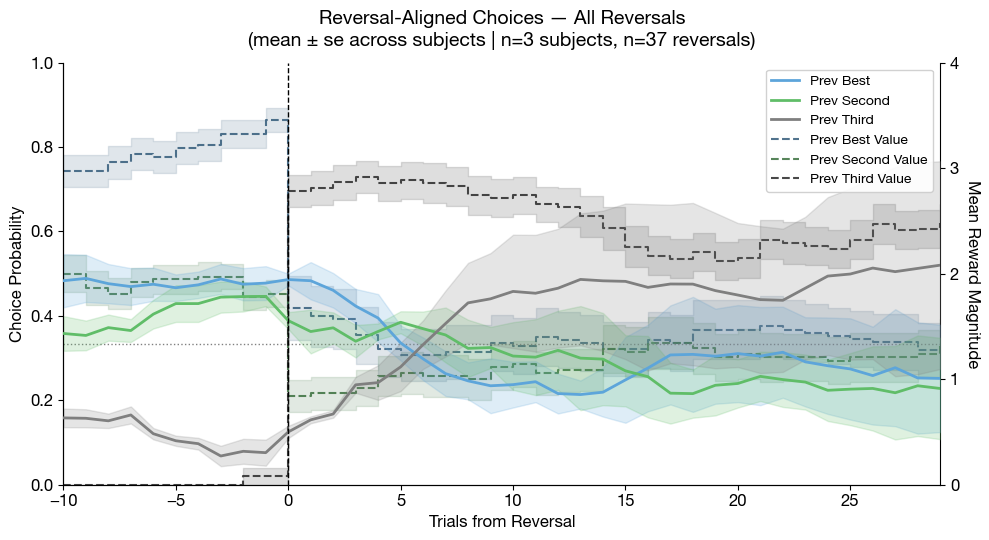

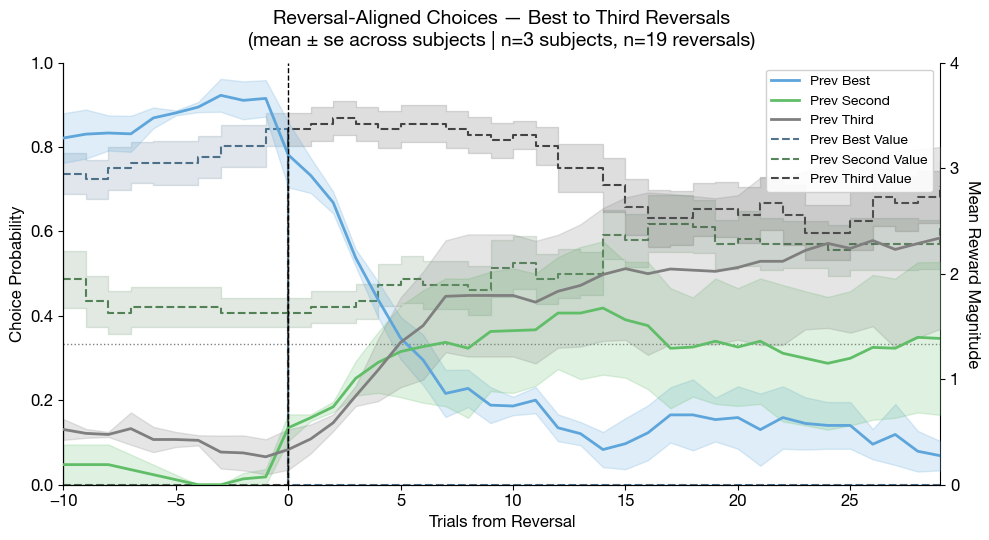

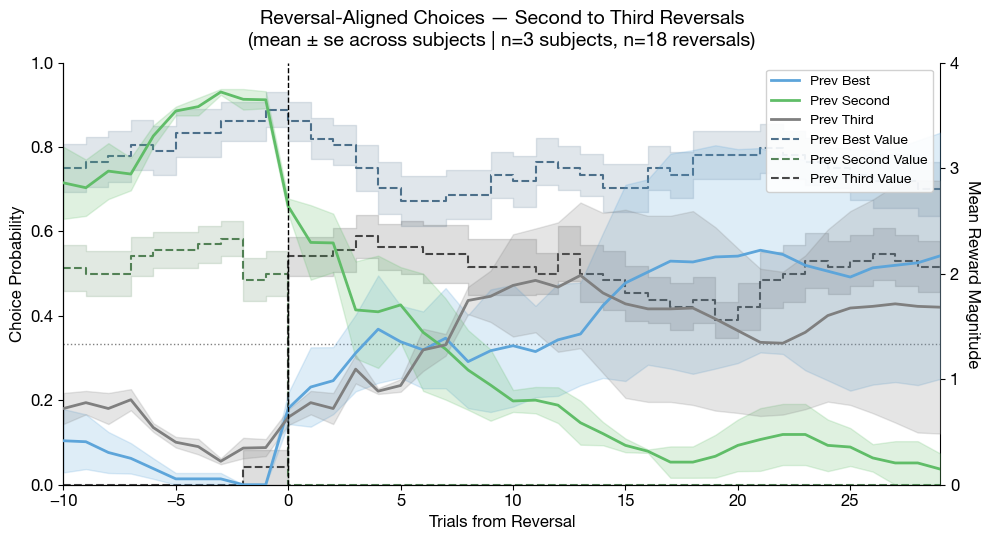

Problem 14


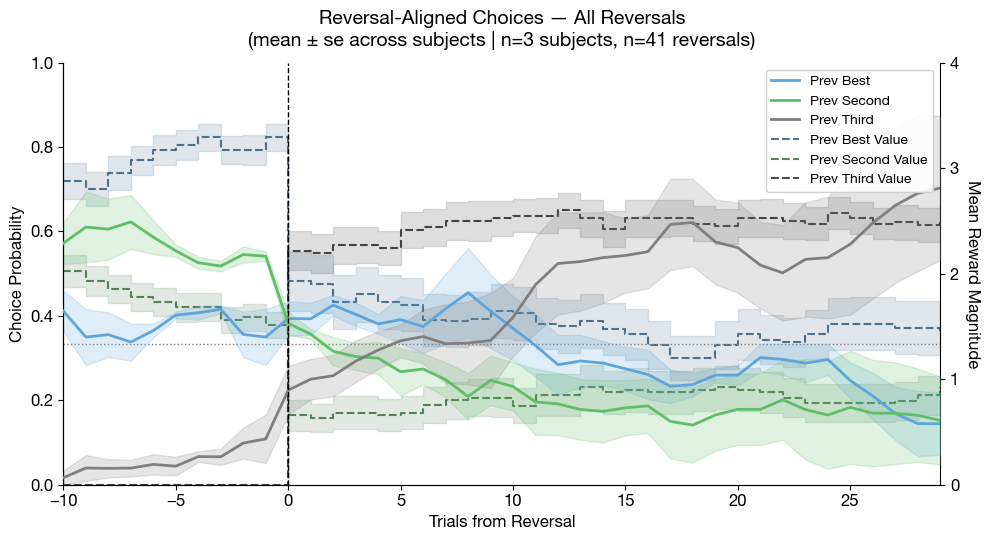

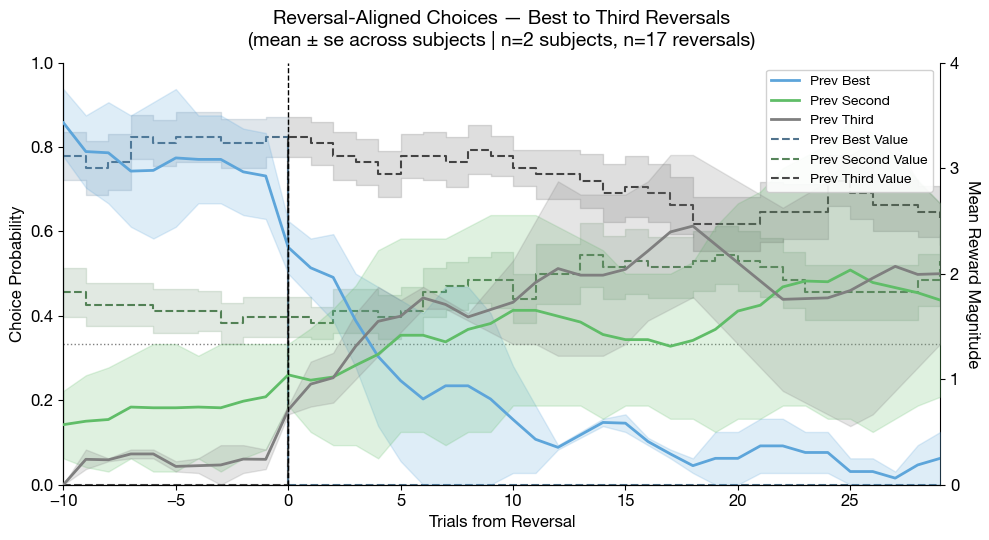

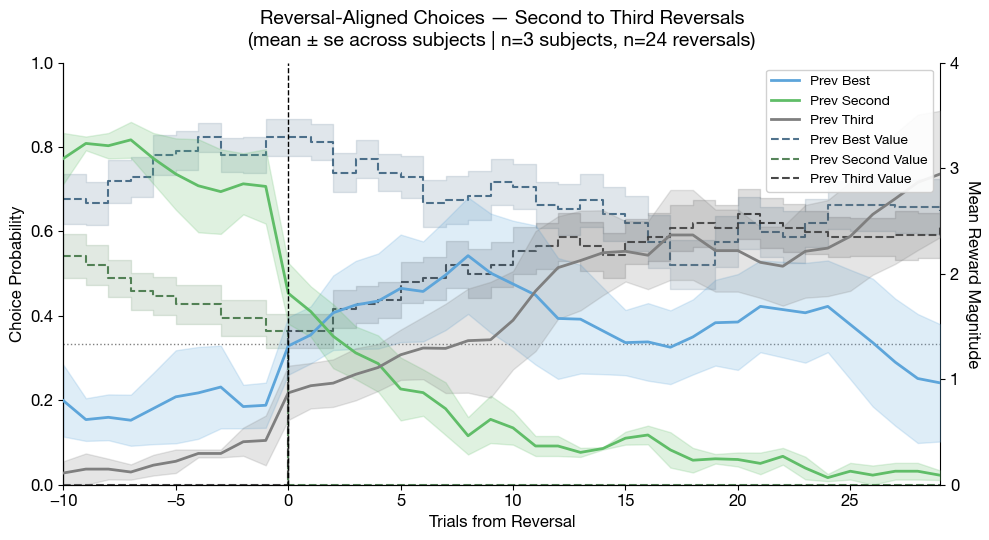

Problem 15


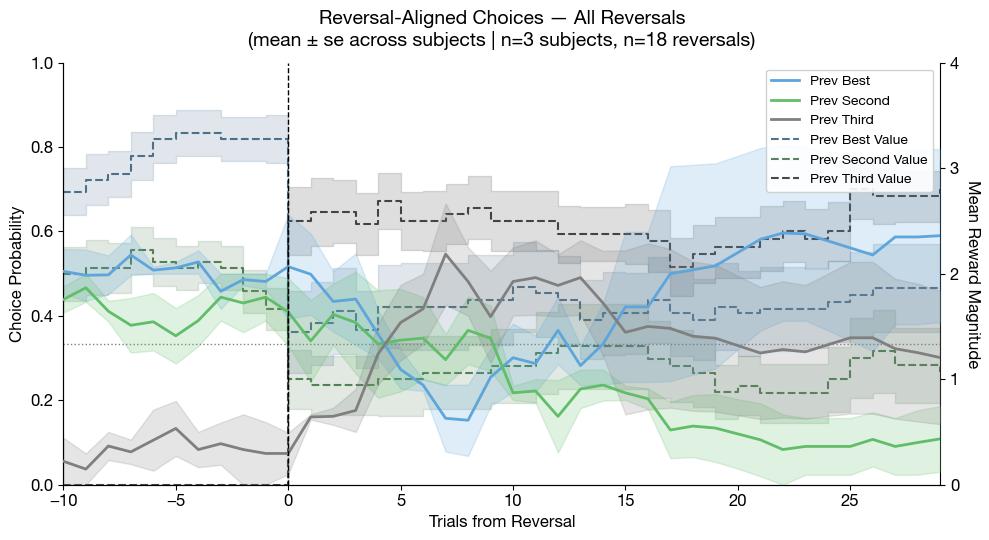

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:369: RuntimeWarning: Mean of empty slice
  "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:370: RuntimeWarning: Mean of empty slice
  "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:371: RuntimeWarning: Mean of empty slice
  "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),


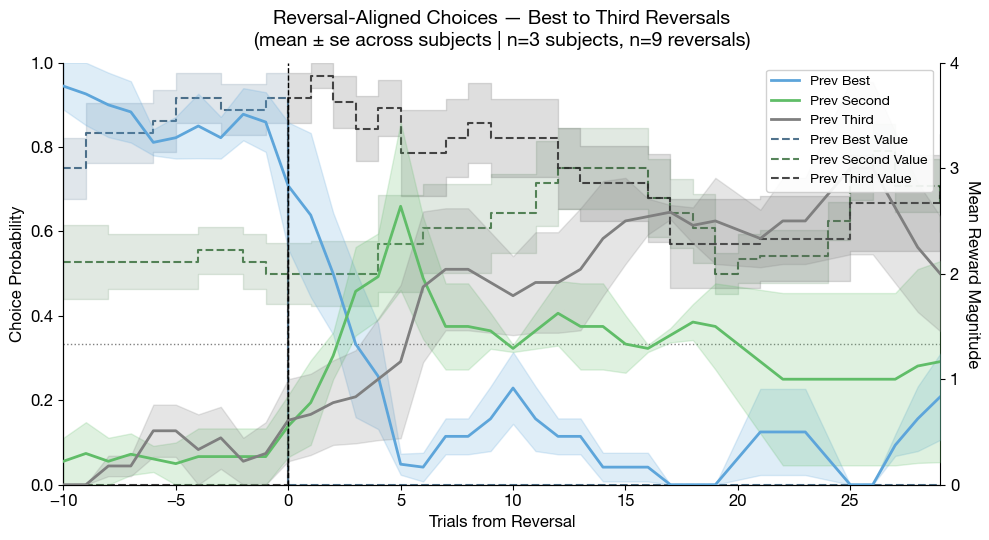

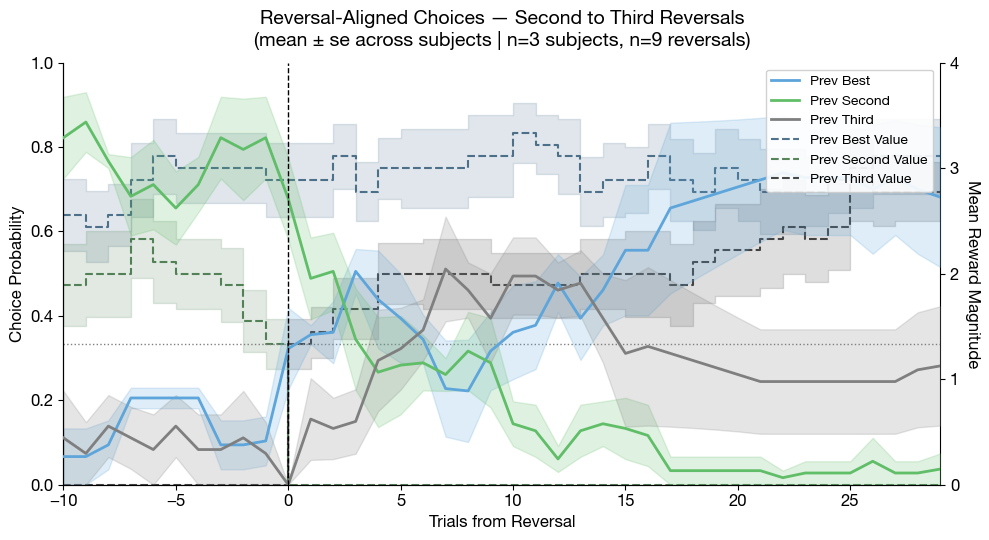

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:369: RuntimeWarning: Mean of empty slice
  "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:370: RuntimeWarning: Mean of empty slice
  "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:371: RuntimeWarning: Mean of empty slice
  "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),
/Users/megyoung/anaconda3/envs/magnitude-bandit-analysis/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Problem 16


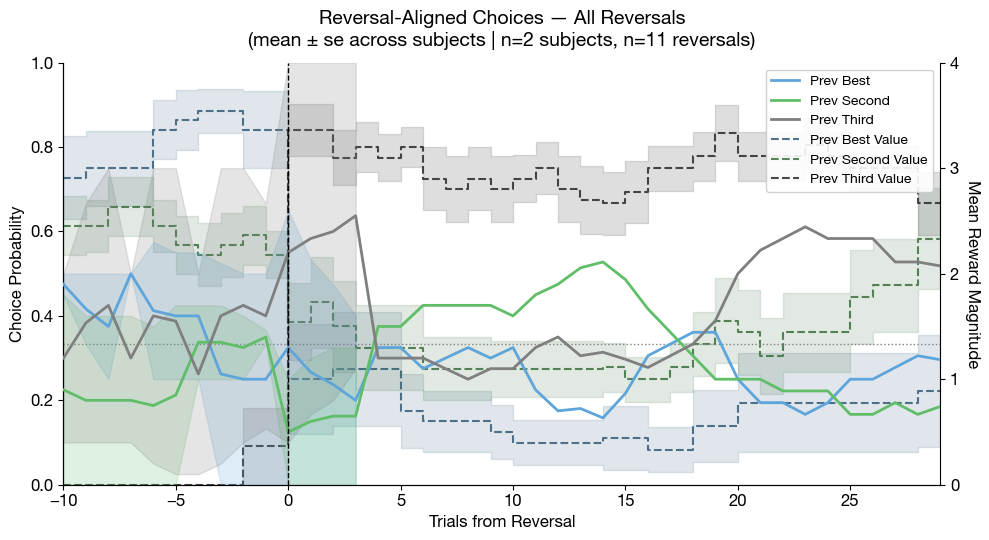

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:369: RuntimeWarning: Mean of empty slice
  "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:370: RuntimeWarning: Mean of empty slice
  "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:371: RuntimeWarning: Mean of empty slice
  "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),
/Users/megyoung/anaconda3/envs/magnitude-bandit-analysis/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


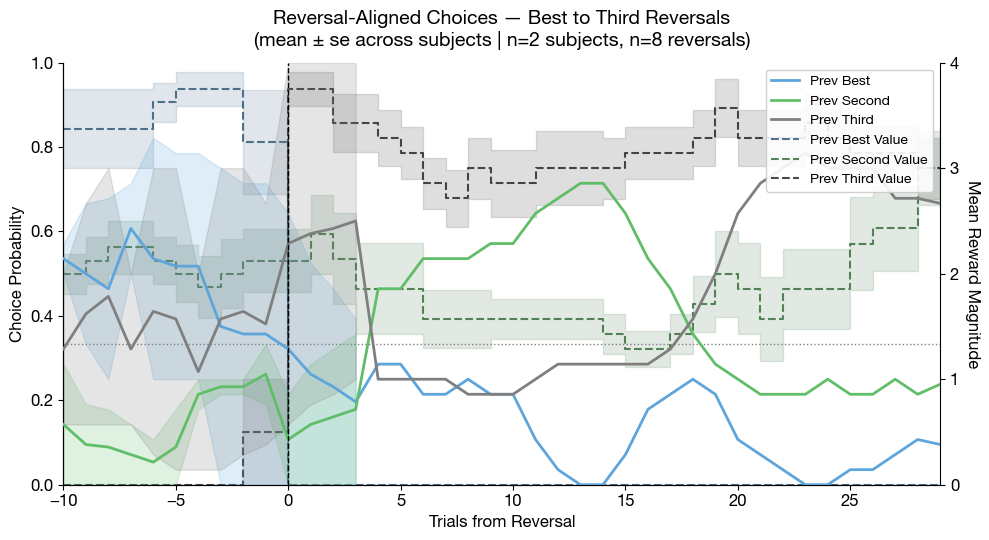

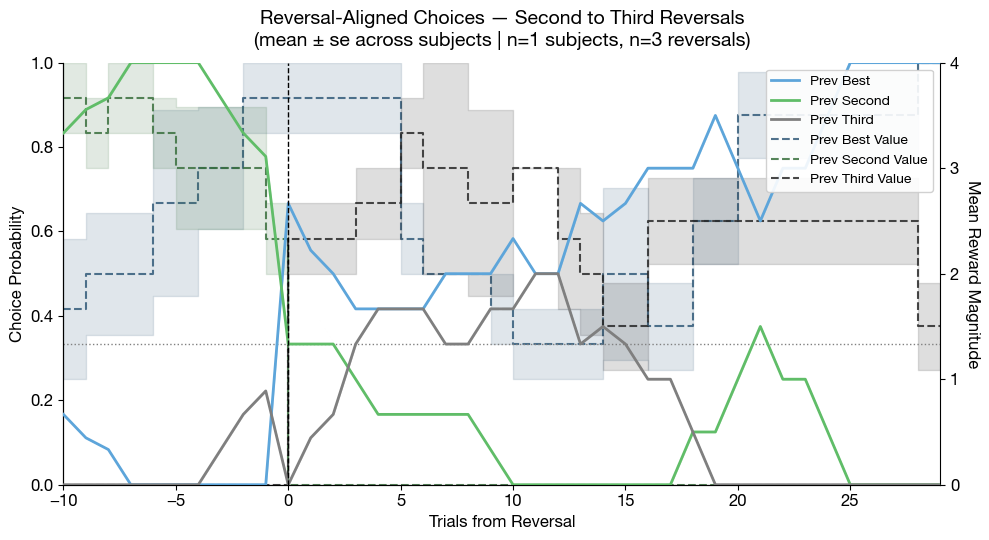

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:369: RuntimeWarning: Mean of empty slice
  "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:370: RuntimeWarning: Mean of empty slice
  "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:371: RuntimeWarning: Mean of empty slice
  "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),
/Users/megyoung/anaconda3/envs/magnitude-bandit-analysis/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Problem 17


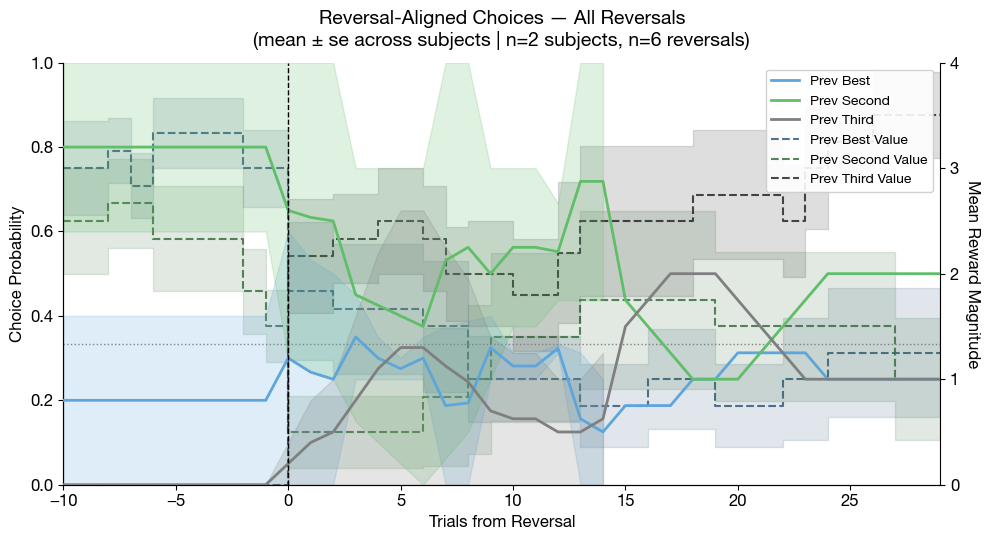

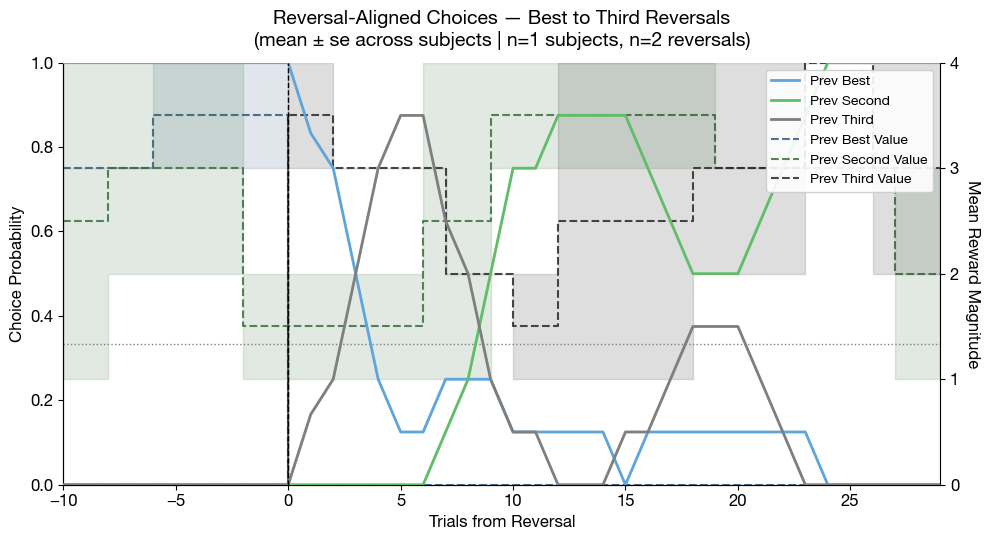

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:369: RuntimeWarning: Mean of empty slice
  "prev_best_mean":  np.nanmean(stacked["prev_best"],  axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:370: RuntimeWarning: Mean of empty slice
  "prev_sec_mean":   np.nanmean(stacked["prev_sec"],   axis=0),
/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_51731/268380587.py:371: RuntimeWarning: Mean of empty slice
  "prev_third_mean": np.nanmean(stacked["prev_third"], axis=0),
/Users/megyoung/anaconda3/envs/magnitude-bandit-analysis/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


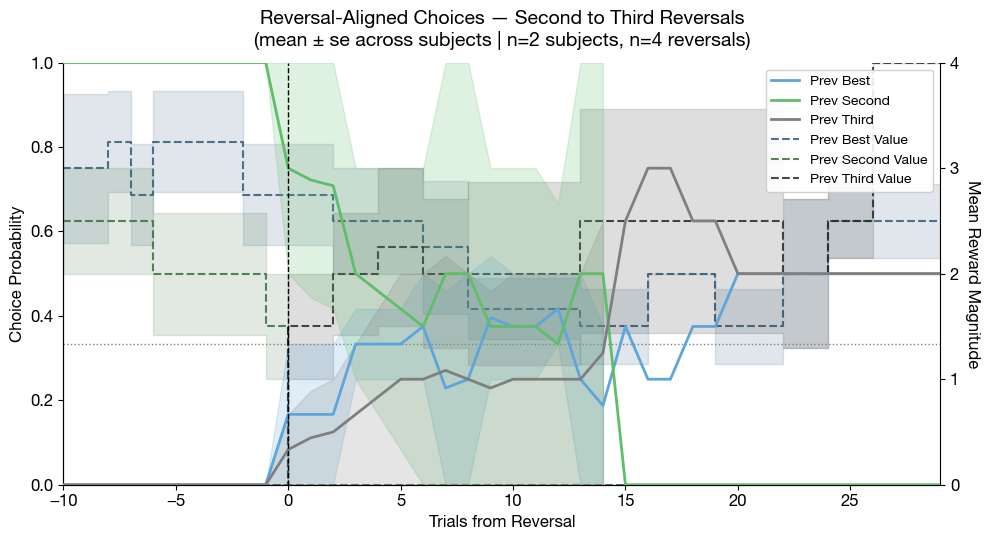

In [14]:
# ---------------------------------------------------------------------------
# Reversal analysis — per-problem AND pooled across problems
# ---------------------------------------------------------------------------

from src.behavior_analysis.merge_across_problems import merge_windows_by_subject

PRE, POST = 10, 30
windows_by_problem_rev = {}   # problem -> enriched reversal_windows

for problem_number, subjects_trials in subjects_trials_by_problem.items():
    if problem_number < CUTOFF_PROBLEM or problem_number > CUTOFF_PROBLEM_HIGH:
        continue

    print(f"Problem {problem_number}")
    problem = f"problem-{problem_number:02d}"

    reversal_windows = get_good_reversal_info(
        subjects_trials, pre=PRE, post=POST, include_first_block=False
    )
    enrich_reversal_windows_with_magnitudes(
        reversal_windows, subjects_trials, pre=PRE, post=POST
    )
    windows_by_problem_rev[problem_number] = reversal_windows

    # --- Per-problem plots ---
    for rev_type in ["all", "best_to_third", "second_to_third"]:
        filtered = filter_reversals_by_type(reversal_windows, rev_type)
        x, per_subject, across = get_choice_probs_around_good_reversals_prev_ranks(
            filtered, pre=PRE, post=POST
        )
        x, per_subject_sm, across_sm = apply_moving_average(
            x, per_subject, window=4, mode="centered"
        )
        plot_reversal_choice_probs(
            x, across_sm, filtered,
            reversal_type=rev_type, use_moving_avg=True, save_path=None,
        )


Pooled: 3 subjects, 113 reversals


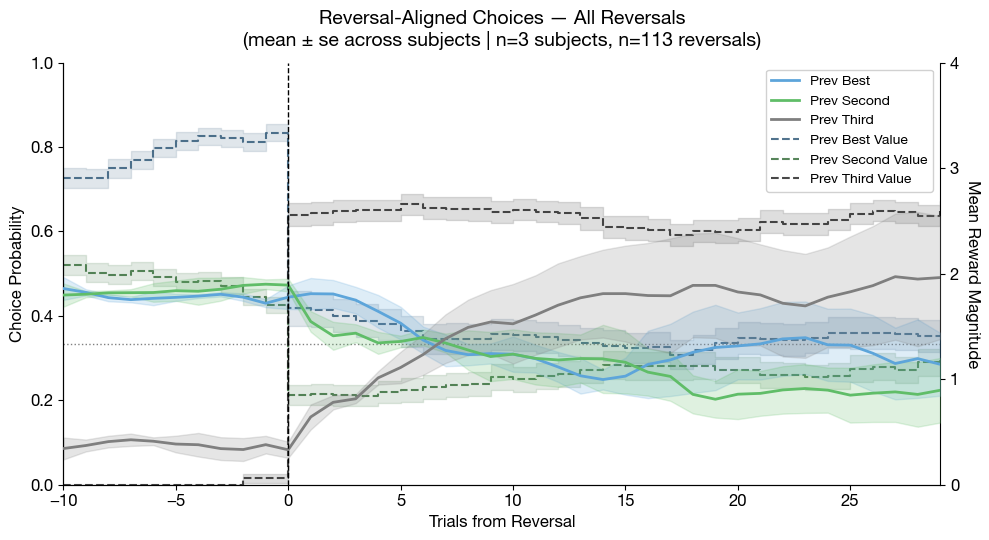

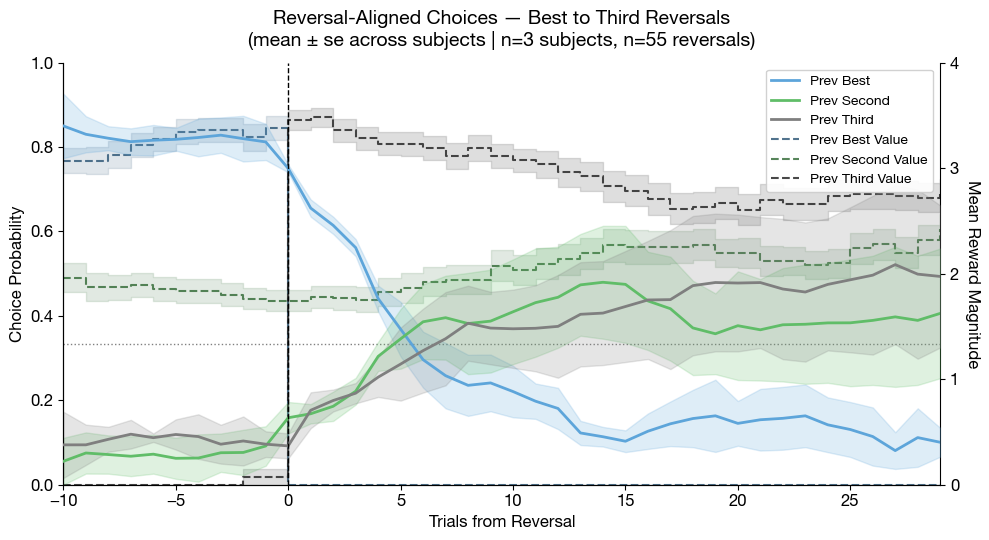

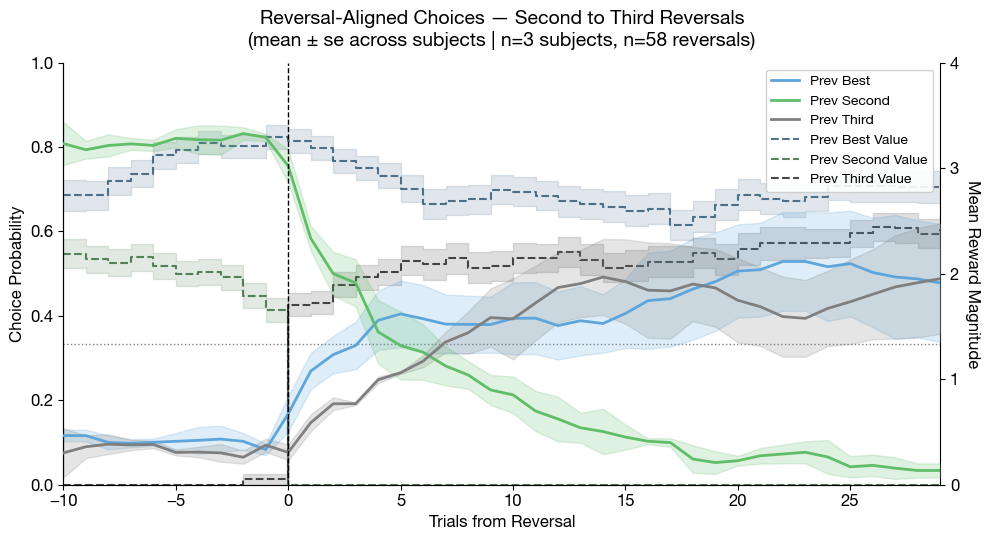

In [15]:
# ---------------------------------------------------------------------------
# Pooled across problems
# ---------------------------------------------------------------------------
reversal_windows_pooled = merge_windows_by_subject(windows_by_problem_rev)

print(f"\nPooled: {len(reversal_windows_pooled)} subjects, "
      f"{sum(len(v) for v in reversal_windows_pooled.values())} reversals")

for rev_type in ["all", "best_to_third", "second_to_third"]:
    filtered = filter_reversals_by_type(reversal_windows_pooled, rev_type)
    x, per_subject, across = get_choice_probs_around_good_reversals_prev_ranks(
        filtered, pre=PRE, post=POST
    )
    x, per_subject_sm, across_sm = apply_moving_average(
        x, per_subject, window=4, mode="trailing"
    )
    plot_reversal_choice_probs(
        x, across_sm, filtered,
        reversal_type=rev_type, use_moving_avg=True, save_path=None,
    )


In [16]:
"""
value_change_analysis.py
========================
Plots choice probabilities (best, second, third) aligned to increases or
decreases in the true or believed reward magnitude of the rank-1 (best) or
rank-2 (second-best) arm, across all trials in a problem.

Public API
----------
    get_value_change_windows(subjects_trials, rank, direction, pre, post,
                             use_believed, use_believed_rank,
                             rank_preserving_only, rank_swap_only,
                             truncate_at_value_change)
    plot_value_change_choice_probs(windows, rank, direction, pre, post,
                                   use_believed, use_believed_rank,
                                   rank_preserving_only, rank_swap_only,
                                   show_individual_mice, save_path)
    run_all_value_change_plots(subjects_trials, pre, post,
                               show_individual_mice, save_dir,
                               truncate_at_value_change)
    assert_truncation_invariant(subjects_trials, pre, post)
    flatten_subjects_trials(subjects_trials)
    diagnose_mid_window_value_changes(subjects_trials, pre, post)
"""

import warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Style
# ---------------------------------------------------------------------------
mpl.rcParams["font.family"]      = "sans-serif"
mpl.rcParams["font.sans-serif"]  = ["Helvetica Neue", "Helvetica", "Arial"]
mpl.rcParams["xtick.labelsize"]  = 12
mpl.rcParams["ytick.labelsize"]  = 12
mpl.rcParams["axes.labelsize"]   = 12
mpl.rcParams["axes.titlesize"]   = 14

COLOR_MAP = {
    "best":        "#5DA5DA",
    "second":      "#60BD68",
    "third":       "#7f7f7f",
    "prev_best":   "#5DA5DA",
    "prev_second": "#60BD68",
}
LABEL_MAP = {
    "best":        "Best",
    "second":      "Second",
    "third":       "Third",
    "prev_best":   "Prev Best",
    "prev_second": "Prev Second Best",
}


# ---------------------------------------------------------------------------
# Believed rank helper
# ---------------------------------------------------------------------------

def _compute_believed_ranks(choices, reward_magnitudes):
    """
    For each trial, compute the believed rank of the chosen arm by re-ranking
    all arms according to their last-seen magnitudes (believed values).

    Returns a list of "best" / "second" / "third" / None per trial.
    None means at least one arm has never been visited yet.
    """
    last_seen             = {}
    believed_chosen_ranks = []

    for i, rm in enumerate(reward_magnitudes):
        choice = choices[i]

        if all(arm in last_seen for arm in rm):
            ranked         = sorted(last_seen.items(), key=lambda kv: kv[1], reverse=True)
            rank_of_choice = None
            for ri, (arm, _) in enumerate(ranked):
                if arm == choice:
                    rank_of_choice = ["best", "second", "third"][min(ri, 2)]
                    break
            believed_chosen_ranks.append(rank_of_choice)
        else:
            believed_chosen_ranks.append(None)

        if choice and choice in rm:
            last_seen[choice] = rm[choice]

    return believed_chosen_ranks


# ---------------------------------------------------------------------------
# Window extraction
# ---------------------------------------------------------------------------

def get_value_change_windows(subjects_trials, rank="best", direction="increase",
                              pre=5, post=5, use_believed=False,
                              use_believed_rank=False,
                              rank_preserving_only=False,
                              rank_swap_only=False,
                              truncate_at_value_change=False):
    """
    Find all trials where the magnitude of the rank-1 ("best") or rank-2
    ("second") arm changes in the specified direction, then extract pre/post
    choice probability windows around each event.

    Parameters
    ----------
    subjects_trials           : dict[subject_id -> dict[session_id -> session_data]]
    rank                      : "best" or "second"
    direction                 : "increase" or "decrease"
    pre, post                 : int, trials before/after the event
    use_believed              : bool
    use_believed_rank         : bool
    rank_preserving_only      : bool
    rank_swap_only            : bool
    truncate_at_value_change  : bool
        If True, post-window trials after a rank swap occurs mid-window are
        set to None and excluded from analysis. The total number of events
        found is identical to truncate_at_value_change=False — only the
        post-window contents differ. Use assert_truncation_invariant() to
        verify this property.

    Returns
    -------
    dict[subject_id -> list[event_dict]]
    """
    if rank_preserving_only and rank_swap_only:
        raise ValueError("rank_preserving_only and rank_swap_only are mutually exclusive.")

    _IMPOSSIBLE_SWAP = {("best", "increase"), ("second", "decrease")}
    if rank_swap_only and (rank, direction) in _IMPOSSIBLE_SWAP:
        raise ValueError(
            f"rank_swap_only=True with rank='{rank}' and direction='{direction}' is "
            f"logically impossible. Valid swap combos are "
            f"(rank='second', direction='increase') and (rank='best', direction='decrease')."
        )

    rank_idx    = {"best": 0, "second": 1}[rank]
    per_subject = {}

    def _rank_order(mag_dict):
        return [arm for arm, _ in sorted(mag_dict.items(),
                                         key=lambda kv: (-kv[1], str(kv[0])))]

    def _is_rank_swap(order_before, order_after):
        if len(order_before) < 2 or len(order_after) < 2:
            return False
        best_before   = order_before[0]
        second_before = order_before[1]
        return (order_after.index(best_before) >= 1 and
                order_after.index(second_before) == 0)

    for subject_id, sessions in subjects_trials.items():
        events = []

        for session_id, sess in sessions.items():
            tv_list = sess.get("trial_variables", [])
            if not tv_list:
                continue
            tv = tv_list[0]

            chosen_ranks      = tv.get("chosen_rank", [])
            reward_magnitudes = tv.get("reward_magnitudes", [])
            choices           = tv.get("choice", [])
            blocks            = tv.get("blocks", [])

            n = min(len(chosen_ranks), len(reward_magnitudes), len(choices))
            if n < 2:
                continue

            if use_believed_rank:
                rank_labels = _compute_believed_ranks(choices[:n], reward_magnitudes[:n])
            else:
                rank_labels = chosen_ranks

            def _same_block(i):
                if len(blocks) < n:
                    return True
                return blocks[i] == blocks[i - 1]

            def _extract_window(i, prev_best_arm=None, prev_second_arm=None):
                """
                Extract pre/post choice label windows around trial i.

                t=0  -> trial i    (first trial with the value change)
                t=-1 -> trial i-1  (last trial before the value change)

                If truncate_at_value_change=True, post-window trials after a
                rank swap are set to None. This does NOT change which events
                are found — only the contents of the post window.
                """
                anchor = i   # t=0 is the first trial with the new value
                if anchor - pre < 0 or anchor + post >= n:
                    return None, None

                old_block = blocks[i - 1] if len(blocks) >= n else None
                new_block = blocks[i]     if len(blocks) >= n else None

                def _get(j):
                    if len(blocks) >= n:
                        expected = new_block if j >= i else old_block
                        if blocks[j] != expected:
                            return None
                    if prev_best_arm is not None:
                        c = choices[j]
                        if c == prev_best_arm:
                            return "prev_best"
                        elif c == prev_second_arm:
                            return "prev_second"
                        else:
                            return "third"
                    return rank_labels[j]

                pre_choices  = [_get(j) for j in range(anchor - pre, anchor)]
                post_choices = [_get(j) for j in range(anchor, anchor + post + 1)]

                if truncate_at_value_change:
                    # Record the ordering BEFORE the triggering event (pre-event state)
                    pre_event_order = _rank_order(reward_magnitudes[anchor - 1])
                    for offset in range(1, len(post_choices)):
                        j = anchor + offset
                        if j < n and reward_magnitudes[j] != reward_magnitudes[j - 1]:
                            order_before = _rank_order(reward_magnitudes[j - 1])
                            order_after  = _rank_order(reward_magnitudes[j])
                            if _is_rank_swap(order_before, order_after):
                                # Only truncate if this swap reverts to the
                                # pre-event ordering (best and second swap back)
                                if (len(order_after) >= 2 and
                                        len(pre_event_order) >= 2 and
                                        order_after[0] == pre_event_order[0] and
                                        order_after[1] == pre_event_order[1]):
                                    for k in range(offset, len(post_choices)):
                                        post_choices[k] = None
                                    break

                return pre_choices, post_choices

            def _apply_rank_filter(order_before, order_after):
                if rank_preserving_only:
                    target_arm = order_before[rank_idx] if len(order_before) > rank_idx else None
                    new_rank   = order_after.index(target_arm) if target_arm in order_after else None
                    return new_rank == rank_idx
                if rank_swap_only:
                    return _is_rank_swap(order_before, order_after)
                return True

            if use_believed:
                last_seen = {}

                for i in range(n):
                    rm     = reward_magnitudes[i]
                    choice = choices[i]

                    sorted_arms = sorted(rm.items(), key=lambda kv: kv[1], reverse=True)
                    target_arm  = (sorted_arms[rank_idx][0]
                                   if len(sorted_arms) > rank_idx else None)

                    if choice == target_arm and target_arm in last_seen:
                        true_mag     = rm[choice]
                        believed_mag = last_seen[target_arm]
                        changed = (true_mag > believed_mag) if direction == "increase" \
                                  else (true_mag < believed_mag)

                        if changed and _same_block(i):
                            passes       = True
                            order_before = None
                            if rank_preserving_only or rank_swap_only:
                                order_before = _rank_order(last_seen)
                                updated      = {**last_seen, choice: true_mag}
                                order_after  = _rank_order(updated)
                                passes       = _apply_rank_filter(order_before, order_after)

                            if passes:
                                pba = (order_before[0]
                                       if rank_swap_only and order_before and len(order_before) > 0
                                       else None)
                                psa = (order_before[1]
                                       if rank_swap_only and order_before and len(order_before) > 1
                                       else None)
                                pre_c, post_c = _extract_window(i,
                                                                 prev_best_arm=pba,
                                                                 prev_second_arm=psa)
                                if pre_c is not None:
                                    events.append({
                                        "subject_id": subject_id,
                                        "session_id": session_id,
                                        "trial_idx":  i,
                                        "pre":        pre_c,
                                        "post":       post_c,
                                    })

                    if choice and choice in rm:
                        last_seen[choice] = rm[choice]

            else:
                def rank_mag(rm):
                    vals = sorted(rm.values(), reverse=True)
                    return vals[rank_idx] if len(vals) > rank_idx else np.nan

                mags = [rank_mag(reward_magnitudes[i]) for i in range(n)]

                for i in range(1, n):
                    if not _same_block(i):
                        continue

                    if reward_magnitudes[i] == reward_magnitudes[i - 1]:
                        continue

                    prev_mag = mags[i - 1]
                    curr_mag = mags[i]

                    if np.isnan(prev_mag) or np.isnan(curr_mag):
                        continue

                    changed = (curr_mag > prev_mag) if direction == "increase" \
                              else (curr_mag < prev_mag)
                    if not changed:
                        continue

                    passes = True
                    if rank_preserving_only or rank_swap_only:
                        order_before = _rank_order(reward_magnitudes[i - 1])
                        order_after  = _rank_order(reward_magnitudes[i])

                        if rank_swap_only:
                            moving_arm = order_before[rank_idx] if len(order_before) > rank_idx else None
                            if moving_arm is None:
                                continue
                            arm_prev  = reward_magnitudes[i - 1].get(moving_arm, np.nan)
                            arm_curr  = reward_magnitudes[i    ].get(moving_arm, np.nan)
                            arm_moved = ((arm_curr > arm_prev) if direction == "increase"
                                         else (arm_curr < arm_prev))
                            if not arm_moved:
                                continue

                        passes = _apply_rank_filter(order_before, order_after)

                    if not passes:
                        continue

                    pba = (order_before[0]
                           if rank_swap_only and len(order_before) > 0 else None)
                    psa = (order_before[1]
                           if rank_swap_only and len(order_before) > 1 else None)
                    pre_c, post_c = _extract_window(i,
                                                     prev_best_arm=pba,
                                                     prev_second_arm=psa)
                    if pre_c is None:
                        continue
                    events.append({
                        "subject_id": subject_id,
                        "session_id": session_id,
                        "trial_idx":  i,
                        "pre":        pre_c,
                        "post":       post_c,
                    })

        if events:
            per_subject[subject_id] = events

    return per_subject


# ---------------------------------------------------------------------------
# Aggregation helper
# ---------------------------------------------------------------------------

def _aggregate_windows(per_subject, pre, post):
    """
    Convert raw choice-rank windows into per-subject mean arrays, then compute
    cross-subject mean and SE.

    Returns
    -------
    x              : trial offset array
    per_subj_means : dict[subject_id -> dict[rank -> array]]
    across         : dict with keys:
        mean, se, num_subjects,
        num_events             — total events (invariant to truncation),
        num_truncated          — events with at least one None in post window
    """
    T = pre + post + 1
    x = np.arange(-pre, post + 1, dtype=float)

    use_swap_labels = False
    outer_break = False
    for events in per_subject.values():
        for ev in events:
            for label in ev["pre"] + ev["post"]:
                if label in ("prev_best", "prev_second"):
                    use_swap_labels = True
                    outer_break = True
                    break
                elif label is not None:
                    # found a standard label — not a swap window
                    outer_break = True
                    break
            if outer_break:
                break
        if outer_break:
            break

    ranks = ["prev_best", "prev_second", "third"] if use_swap_labels \
            else ["best", "second", "third"]

    per_subj_means = {}

    for subj, events in per_subject.items():
        accum = {r: np.full((len(events), T), np.nan) for r in ranks}

        for ei, ev in enumerate(events):
            choices = ev["pre"] + ev["post"]
            for ti, cr in enumerate(choices):
                if cr is None:
                    continue
                for r in ranks:
                    accum[r][ei, ti] = 1.0 if cr == r else 0.0

        per_subj_means[subj] = {r: np.nanmean(accum[r], axis=0) for r in ranks}

    subj_list = list(per_subj_means.keys())
    n         = len(subj_list)

    across_mean, across_se = {}, {}
    for r in ranks:
        if subj_list:
            stack          = np.vstack([per_subj_means[s][r] for s in subj_list])
            across_mean[r] = np.nanmean(stack, axis=0)
            across_se[r]   = (np.nanstd(stack, axis=0, ddof=1) / np.sqrt(n)
                               if n > 1 else np.zeros(T))
        else:
            across_mean[r] = np.full(T, np.nan)
            across_se[r]   = np.full(T, np.nan)

    num_events    = sum(len(evs) for evs in per_subject.values())
    num_truncated = sum(
        1
        for evs in per_subject.values()
        for ev in evs
        if any(v is None for v in ev["post"])
    )

    across = {
        "mean":          across_mean,
        "se":            across_se,
        "num_subjects":  n,
        "num_events":    num_events,    # invariant to truncation
        "num_truncated": num_truncated, # 0 when truncate_at_value_change=False
    }

    return x, per_subj_means, across


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def plot_value_change_choice_probs(
    windows,
    rank="best",
    direction="increase",
    pre=5,
    post=5,
    use_believed=False,
    use_believed_rank=False,
    rank_preserving_only=False,
    rank_swap_only=False,
    show_individual_mice=False,
    save_path=None,
):
    rank_label  = "Best" if rank == "best" else "Second-Best"
    dir_label   = "Increase" if direction == "increase" else "Decrease"
    value_label = "Believed" if use_believed else "True"
    rank_suffix = " (Believed Rank)" if use_believed_rank else ""

    if rank_preserving_only:
        filter_suffix = " [Rank-Preserving Only]"
    elif rank_swap_only:
        filter_suffix = " [Rank-Swap Only]"
    else:
        filter_suffix = ""

    x, per_subj_means, across = _aggregate_windows(windows, pre, post)
    n_subj        = across["num_subjects"]
    n_events      = across["num_events"]      # total events, invariant to truncation
    n_truncated   = across["num_truncated"]   # events with post-window truncation

    # derive rank_keys from actual data to handle swap vs non-swap correctly
    rank_keys = list(across["mean"].keys())

    fig, ax = plt.subplots(figsize=(8, 5))

    for r in rank_keys:
        mean = across["mean"][r]
        se   = across["se"][r]
        col  = COLOR_MAP[r]

        if show_individual_mice:
            for subj_means in per_subj_means.values():
                y_subj = subj_means[r]
                m = np.isfinite(y_subj)
                if m.any():
                    ax.plot(x[m], y_subj[m], color="gray", lw=0.8, alpha=0.4, zorder=1)

        m = np.isfinite(mean)
        if m.any():
            ax.plot(x[m], mean[m], color=col, lw=2.2, label=LABEL_MAP[r], zorder=3)
            ax.fill_between(x, mean - se, mean + se, where=m,
                            alpha=0.2, color=col, zorder=2)

    ax.axvline(0,     color="black", ls="--", lw=1, zorder=4)
    ax.axhline(1 / 3, color="gray",  ls=":",  lw=1, zorder=1)
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(0, 1)
    ax.set_xlabel("Trials from Value Change", fontsize=12)
    ax.set_ylabel("Choice Probability", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", fontsize=10, framealpha=0.9)

    # n_events is always the total number of events regardless of truncation;
    # if any post windows were truncated, note how many
    if n_truncated > 0:
        events_str = f"n={n_events} events ({n_truncated} post-truncated)"
    else:
        events_str = f"n={n_events} events"
    events_str = f"n={n_events} events"

    title = (
        f"Choice Probabilities Aligned to {rank_label} {value_label} Value"
        f" {dir_label}{rank_suffix}{filter_suffix}\n"
        f"(mean ± se across subjects | "
        f"n={n_subj} subjects, {events_str})"
    )
    ax.set_title(title, pad=12)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        plt.tight_layout()

    if save_path:
        from pathlib import Path
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(str(base) + ".pdf", bbox_inches="tight")
        fig.savefig(str(base) + ".png", dpi=300, bbox_inches="tight")
    else:
        plt.show()

    plt.close(fig)


# ---------------------------------------------------------------------------
# Assert: truncation must not change event count
# ---------------------------------------------------------------------------

def assert_truncation_invariant(subjects_trials, pre=5, post=15):
    """
    For all conditions, assert that truncate_at_value_change=True and =False
    produce exactly the same number of events. Raises AssertionError if not.

    Truncation should only affect the contents of post windows (setting some
    trials to None), never which events are discovered.
    """
    configs = []
    for rank in ["best", "second"]:
        for direction in ["increase", "decrease"]:
            for rank_filter in ["all", "rank_preserving", "rank_swap"]:
                if rank_filter == "rank_swap" and (rank, direction) in {
                    ("best", "increase"), ("second", "decrease")
                }:
                    continue
                configs.append(dict(
                    rank=rank,
                    direction=direction,
                    rank_preserving_only=(rank_filter == "rank_preserving"),
                    rank_swap_only=(rank_filter == "rank_swap"),
                    label=f"{rank}/{direction}/{rank_filter}",
                ))

    all_ok = True
    for cfg in configs:
        kwargs = dict(
            rank=cfg["rank"],
            direction=cfg["direction"],
            pre=pre,
            post=post,
            rank_preserving_only=cfg["rank_preserving_only"],
            rank_swap_only=cfg["rank_swap_only"],
        )
        w_false = get_value_change_windows(subjects_trials,
                                           truncate_at_value_change=False, **kwargs)
        w_true  = get_value_change_windows(subjects_trials,
                                           truncate_at_value_change=True,  **kwargs)

        n_false = sum(len(v) for v in w_false.values())
        n_true  = sum(len(v) for v in w_true.values())

        if n_false != n_true:
            print(f"[FAIL] {cfg['label']}: truncate=False → {n_false}, "
                  f"truncate=True → {n_true} (diff={n_true - n_false})")
            all_ok = False
        else:
            print(f"[OK]   {cfg['label']}: {n_false} events")

    assert all_ok, (
        "Event count differs between truncate_at_value_change=True and =False. "
        "Truncation should only affect post-window contents, not event discovery."
    )
    print("\nAll conditions passed: truncation does not change event count.")


# ---------------------------------------------------------------------------
# Diagnostic
# ---------------------------------------------------------------------------

def diagnose_mid_window_value_changes(subjects_trials, pre=5, post=15):
    """
    For each value-change condition, count what fraction of post windows
    contain at least one additional value change, and of those, what fraction
    involve a rank swap (best/second identity swap).

    Returns
    -------
    dict[condition_label -> {
        "n_events":          int,
        "n_contaminated":    int,
        "frac_contaminated": float,
        "n_rank_swap":       int,
        "frac_rank_swap":    float,
    }]
    """
    def _rank_order(mag_dict):
        return [arm for arm, _ in sorted(mag_dict.items(),
                                         key=lambda kv: (-kv[1], str(kv[0])))]

    def _is_rank_swap(order_before, order_after):
        if len(order_before) < 2 or len(order_after) < 2:
            return False
        best_before   = order_before[0]
        second_before = order_before[1]
        return (order_after.index(best_before) >= 1 and
                order_after.index(second_before) == 0)

    configs = []
    for rank in ["best", "second"]:
        for direction in ["increase", "decrease"]:
            for rank_filter in ["all", "rank_preserving", "rank_swap"]:
                if rank_filter == "rank_swap" and (rank, direction) in {
                    ("best", "increase"), ("second", "decrease")
                }:
                    continue
                configs.append(dict(
                    rank=rank,
                    direction=direction,
                    rank_preserving_only=(rank_filter == "rank_preserving"),
                    rank_swap_only=(rank_filter == "rank_swap"),
                    label=f"{rank}/{direction}/{rank_filter}",
                ))

    results = {}

    for cfg in configs:
        windows = get_value_change_windows(
            subjects_trials,
            rank=cfg["rank"],
            direction=cfg["direction"],
            pre=pre,
            post=post,
            use_believed=False,
            use_believed_rank=False,
            rank_preserving_only=cfg["rank_preserving_only"],
            rank_swap_only=cfg["rank_swap_only"],
            truncate_at_value_change=False,  # always check untruncated windows
        )

        n_events       = 0
        n_contaminated = 0
        n_rank_swap    = 0

        for subject_id, events in windows.items():
            rm_full = []
            for sess in subjects_trials.get(subject_id, {}).values():
                tv_list = sess.get("trial_variables", [])
                if tv_list:
                    rm_full.extend(tv_list[0].get("reward_magnitudes", []))

            for ev in events:
                n_events    += 1
                trial_idx    = ev["trial_idx"]
                contaminated = False
                has_swap     = False

                for offset in range(1, post + 1):
                    j = trial_idx + offset
                    if j >= len(rm_full) or j - 1 >= len(rm_full):
                        break
                    if rm_full[j] != rm_full[j - 1]:
                        contaminated = True
                        order_before = _rank_order(rm_full[j - 1])
                        order_after  = _rank_order(rm_full[j])
                        if _is_rank_swap(order_before, order_after):
                            has_swap = True
                        break

                if contaminated:
                    n_contaminated += 1
                    if has_swap:
                        n_rank_swap += 1

        frac_cont = n_contaminated / n_events       if n_events > 0       else float("nan")
        frac_swap = n_rank_swap    / n_contaminated if n_contaminated > 0 else float("nan")

        results[cfg["label"]] = {
            "n_events":          n_events,
            "n_contaminated":    n_contaminated,
            "frac_contaminated": frac_cont,
            "n_rank_swap":       n_rank_swap,
            "frac_rank_swap":    frac_swap,
        }

        print(f"  {cfg['label']:40s} "
              f"contaminated: {n_contaminated:4d}/{n_events:4d} ({frac_cont*100:5.1f}%)  |  "
              f"of which rank swap: {n_rank_swap:4d} ({frac_swap*100:5.1f}%)")

    return results


# ---------------------------------------------------------------------------
# Runner
# ---------------------------------------------------------------------------

def run_all_value_change_plots(subjects_trials, pre=5, post=5,
                                show_individual_mice=False, save_dir=None,
                                truncate_at_value_change=False):
    from pathlib import Path

    configs = []
    for rank in ["best", "second"]:
        for direction in ["increase", "decrease"]:
            for rank_filter in ["all", "rank_preserving", "rank_swap"]:
                if rank_filter == "rank_swap" and (rank, direction) in {
                    ("best", "increase"), ("second", "decrease")
                }:
                    continue
                configs.append(dict(
                    rank=rank,
                    direction=direction,
                    use_believed=False,
                    use_believed_rank=False,
                    rank_preserving_only=(rank_filter == "rank_preserving"),
                    rank_swap_only=(rank_filter == "rank_swap"),
                ))

    for cfg in configs:
        rank                 = cfg["rank"]
        direction            = cfg["direction"]
        use_believed         = cfg["use_believed"]
        use_believed_rank    = cfg["use_believed_rank"]
        rank_preserving_only = cfg["rank_preserving_only"]
        rank_swap_only       = cfg["rank_swap_only"]

        windows = get_value_change_windows(
            subjects_trials,
            rank=rank,
            direction=direction,
            pre=pre,
            post=post,
            use_believed=use_believed,
            use_believed_rank=use_believed_rank,
            rank_preserving_only=rank_preserving_only,
            rank_swap_only=rank_swap_only,
            truncate_at_value_change=truncate_at_value_change,
        )

        if not windows:
            filter_str = ("rank_preserving" if rank_preserving_only
                          else "rank_swap" if rank_swap_only
                          else "all_events")
            print(f"[SKIP] No events: rank={rank}, direction={direction}, "
                  f"filter={filter_str}")
            continue

        save_path = None
        if save_dir is not None:
            value_str  = "true_value"
            filter_str = ("_rank_preserving" if rank_preserving_only
                          else "_rank_swap" if rank_swap_only
                          else "_all_events")
            fname      = f"{rank}_{direction}_{value_str}{filter_str}"
            save_path  = str(Path(save_dir) / fname)

        plot_value_change_choice_probs(
            windows,
            rank=rank,
            direction=direction,
            pre=pre,
            post=post,
            use_believed=use_believed,
            use_believed_rank=use_believed_rank,
            rank_preserving_only=rank_preserving_only,
            rank_swap_only=rank_swap_only,
            show_individual_mice=show_individual_mice,
            save_path=save_path,
        )


# ---------------------------------------------------------------------------
# Utilities
# ---------------------------------------------------------------------------

def flatten_subjects_trials(subjects_trials):
    """
    Convert:
        {problem_id: {animal_id: {session_id: session_data}}}
    to:
        {animal_id: {session_id: session_data}}

    Sessions are prefixed with problem_id to avoid collisions.
    """
    flat = {}
    for problem_id, animals in subjects_trials.items():
        for animal_id, sessions in animals.items():
            if animal_id not in flat:
                flat[animal_id] = {}
            for session_id, session_data in sessions.items():
                flat_key = f"prob{problem_id}__{session_id}"
                flat[animal_id][flat_key] = session_data
    return flat

In [17]:
subjects_trials_by_problem.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18])

In [18]:
curr_subjects_trials_by_problem.keys()

NameError: name 'curr_subjects_trials_by_problem' is not defined

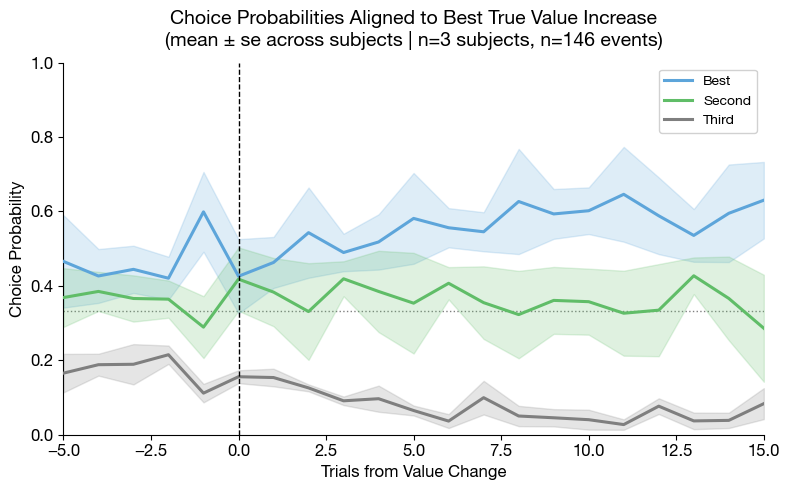

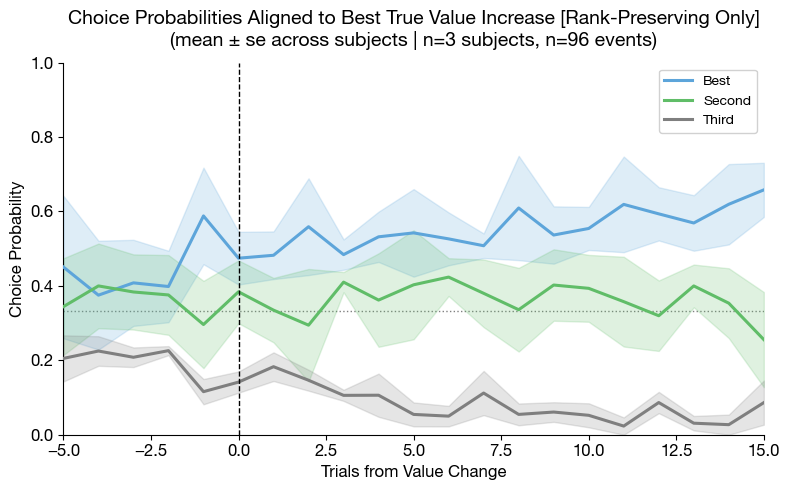

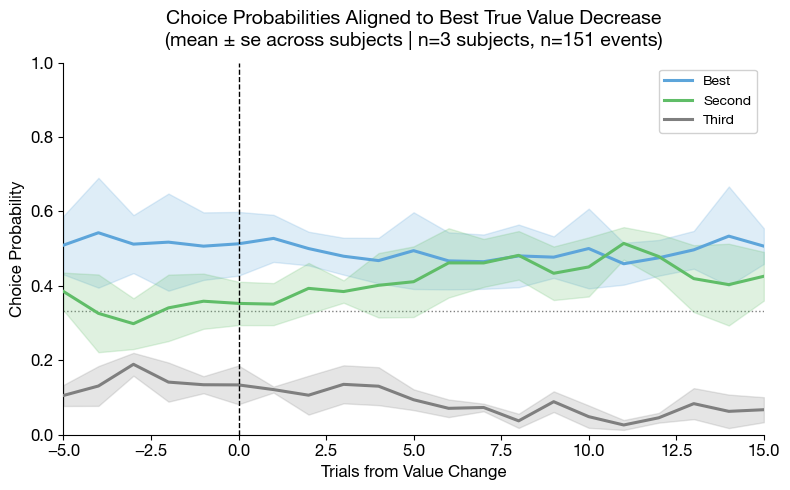

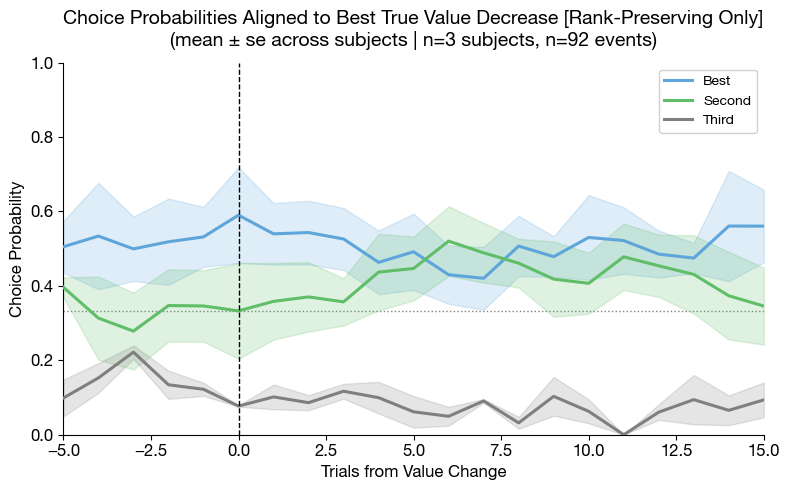

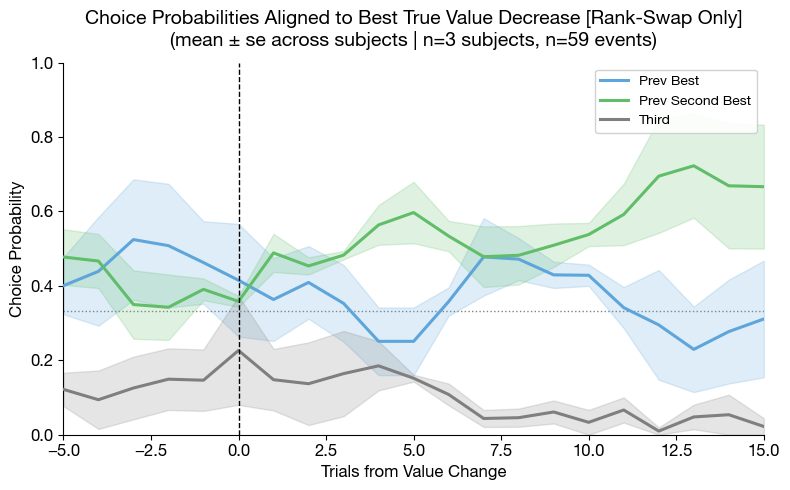

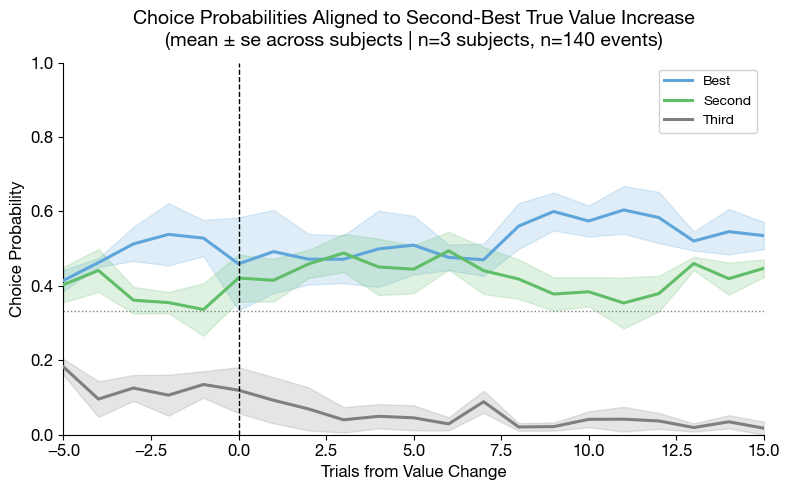

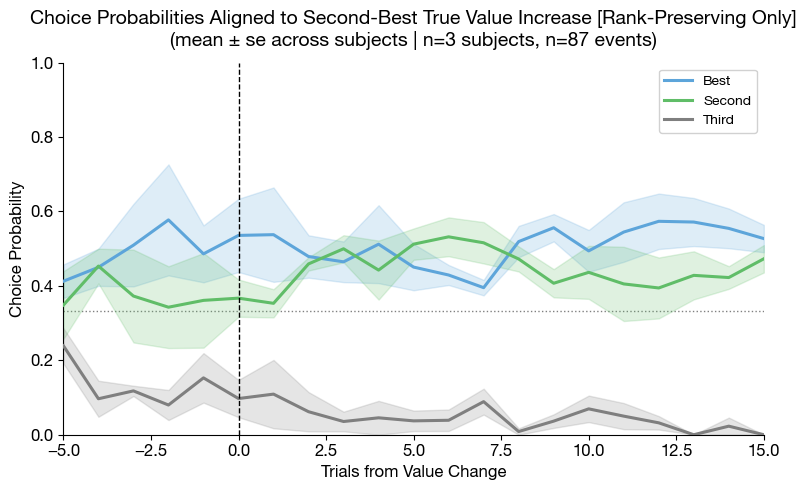

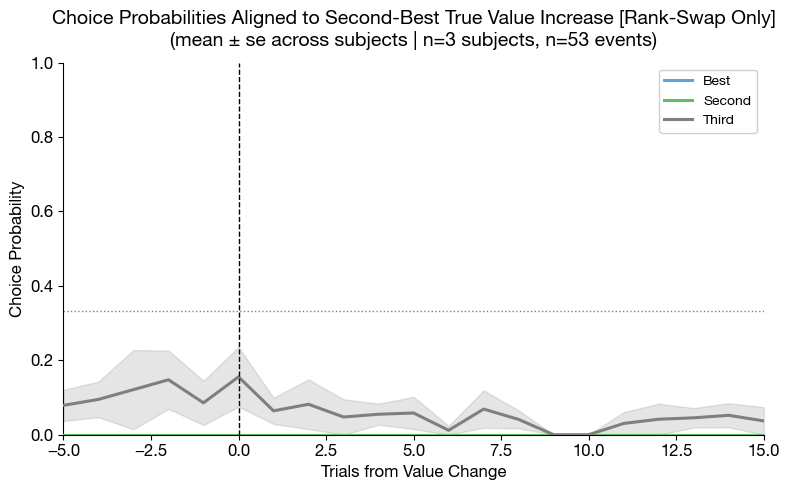

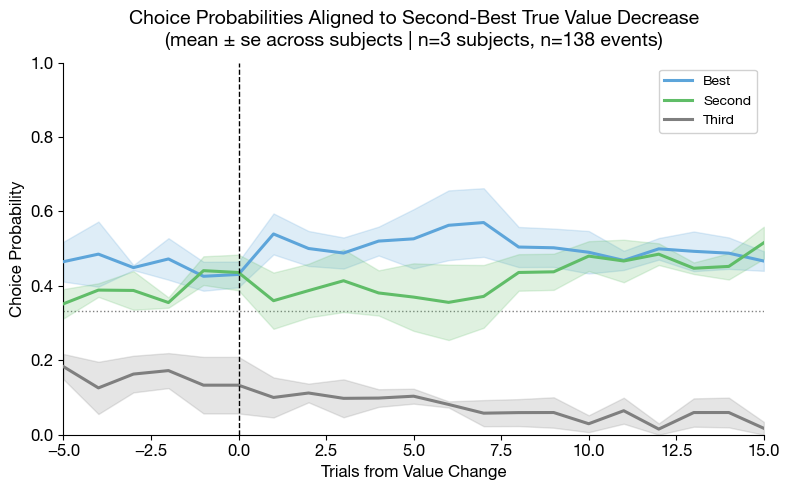

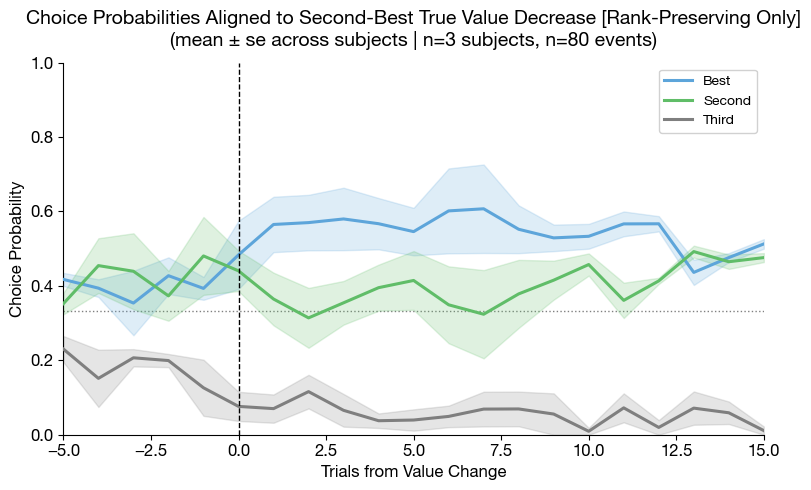

In [ ]:
curr_subjects_trials_by_problem = {}
for p in subjects_trials_by_problem.keys():
    if p < CUTOFF_PROBLEM or p > CUTOFF_PROBLEM_HIGH:
        continue
    curr_subjects_trials_by_problem[p] = subjects_trials_by_problem[p].copy()
subjects_trials_flat = flatten_subjects_trials(curr_subjects_trials_by_problem)
run_all_value_change_plots(subjects_trials_flat, pre=5, post=15, truncate_at_value_change=False)

In [ ]:
def diagnose_mid_window_value_changes(subjects_trials, pre=5, post=15):
    """
    For each value-change condition, count what fraction of post windows
    contain at least one additional value change, and of those, what fraction
    involve a rank swap (best/second identity swap) in the post window.

    Returns
    -------
    dict[condition_label -> {
        "n_events":             int,
        "n_contaminated":       int,
        "frac_contaminated":    float,
        "n_rank_swap":          int,   # of contaminated events, how many involve a rank swap
        "frac_rank_swap":       float, # fraction of contaminated events with a rank swap
    }]
    """
    def _rank_order(mag_dict):
        return [arm for arm, _ in sorted(mag_dict.items(),
                                         key=lambda kv: (-kv[1], str(kv[0])))]

    def _is_rank_swap(order_before, order_after):
        if len(order_before) < 2 or len(order_after) < 2:
            return False
        best_before   = order_before[0]
        second_before = order_before[1]
        return (order_after.index(best_before) >= 1 and
                order_after.index(second_before) == 0)

    configs = []
    for rank in ["best", "second"]:
        for direction in ["increase", "decrease"]:
            for rank_filter in ["all", "rank_preserving", "rank_swap"]:
                if rank_filter == "rank_swap" and (rank, direction) in {
                    ("best", "increase"), ("second", "decrease")
                }:
                    continue
                configs.append(dict(
                    rank=rank,
                    direction=direction,
                    rank_preserving_only=(rank_filter == "rank_preserving"),
                    rank_swap_only=(rank_filter == "rank_swap"),
                    label=f"{rank}/{direction}/{rank_filter}",
                ))

    results = {}

    for cfg in configs:
        windows = get_value_change_windows(
            subjects_trials,
            rank=cfg["rank"],
            direction=cfg["direction"],
            pre=pre,
            post=post,
            use_believed=False,
            use_believed_rank=False,
            rank_preserving_only=cfg["rank_preserving_only"],
            rank_swap_only=cfg["rank_swap_only"],
        )

        n_events       = 0
        n_contaminated = 0
        n_rank_swap    = 0

        for subject_id, events in windows.items():
            # build full reward_magnitudes sequence for this subject
            rm_full = []
            for sess in subjects_trials.get(subject_id, {}).values():
                tv_list = sess.get("trial_variables", [])
                if tv_list:
                    rm_full.extend(tv_list[0].get("reward_magnitudes", []))

            for ev in events:
                n_events += 1
                trial_idx    = ev["trial_idx"]
                contaminated = False
                has_swap     = False

                for offset in range(1, post + 1):
                    j = trial_idx + offset
                    if j >= len(rm_full) or j - 1 >= len(rm_full):
                        break
                    if rm_full[j] != rm_full[j - 1]:
                        contaminated = True
                        # check if this mid-window change is a rank swap
                        order_before = _rank_order(rm_full[j - 1])
                        order_after  = _rank_order(rm_full[j])
                        if _is_rank_swap(order_before, order_after):
                            has_swap = True
                        break   # only flag first change per window

                if contaminated:
                    n_contaminated += 1
                    if has_swap:
                        n_rank_swap += 1

        frac_cont = n_contaminated / n_events if n_events > 0 else float("nan")
        frac_swap = n_rank_swap / n_contaminated if n_contaminated > 0 else float("nan")

        results[cfg["label"]] = {
            "n_events":          n_events,
            "n_contaminated":    n_contaminated,
            "frac_contaminated": frac_cont,
            "n_rank_swap":       n_rank_swap,
            "frac_rank_swap":    frac_swap,
        }

        print(f"  {cfg['label']:40s} "
              f"contaminated: {n_contaminated:4d}/{n_events:4d} ({frac_cont*100:5.1f}%)  |  "
              f"of which rank swap: {n_rank_swap:4d} ({frac_swap*100:5.1f}%)")

    return results

subjects_trials_flat = flatten_subjects_trials(subjects_trials_by_problem)
print("Mid-window value change contamination by condition:\n")
contamination = diagnose_mid_window_value_changes(subjects_trials_flat, pre=5, post=15)

Mid-window value change contamination by condition:

  best/increase/all                        contaminated:  114/ 736 ( 15.5%)  |  of which rank swap:   95 ( 83.3%)
  best/increase/rank_preserving            contaminated:   76/ 446 ( 17.0%)  |  of which rank swap:   62 ( 81.6%)
  best/decrease/all                        contaminated:  105/ 704 ( 14.9%)  |  of which rank swap:   84 ( 80.0%)
  best/decrease/rank_preserving            contaminated:   72/ 454 ( 15.9%)  |  of which rank swap:   58 ( 80.6%)
  best/decrease/rank_swap                  contaminated:   33/ 250 ( 13.2%)  |  of which rank swap:   26 ( 78.8%)
  second/increase/all                      contaminated:  117/ 726 ( 16.1%)  |  of which rank swap:   97 ( 82.9%)
  second/increase/rank_preserving          contaminated:   78/ 428 ( 18.2%)  |  of which rank swap:   63 ( 80.8%)
  second/increase/rank_swap                contaminated:   39/ 298 ( 13.1%)  |  of which rank swap:   34 ( 87.2%)
  second/decrease/all              

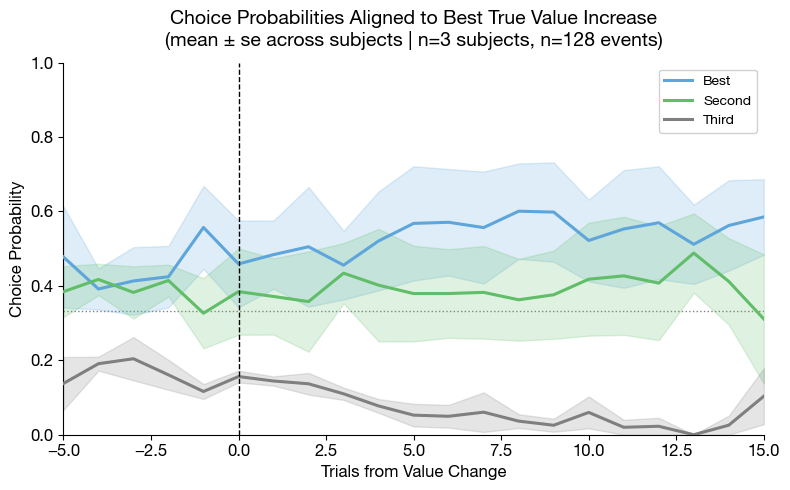

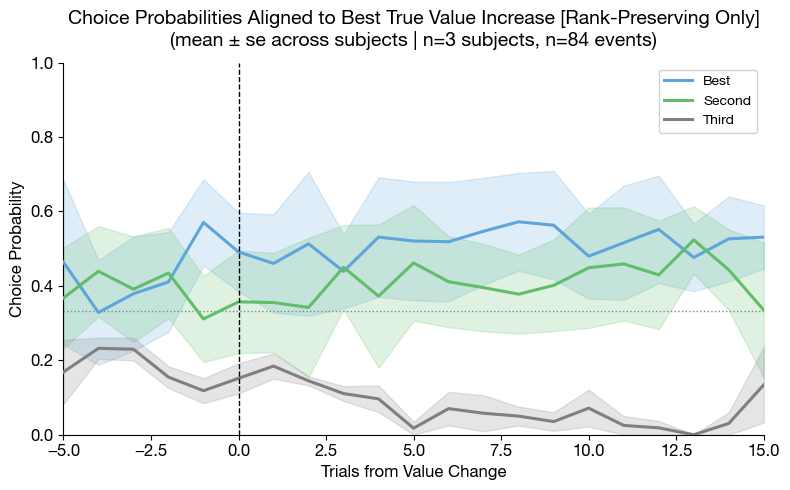

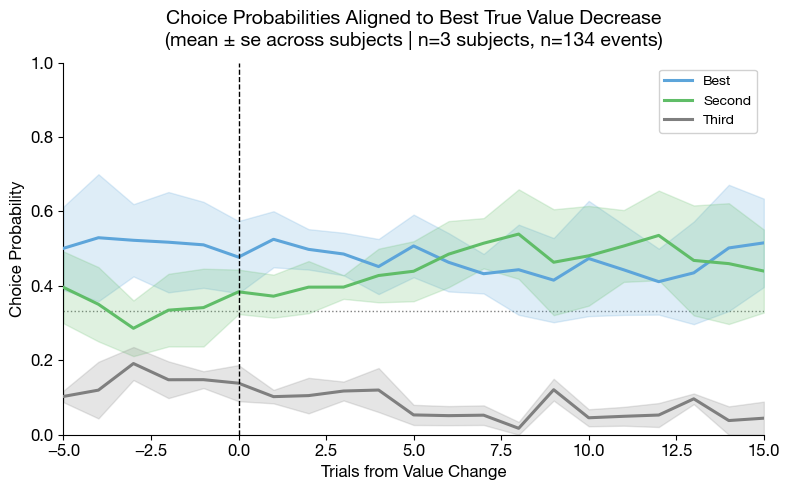

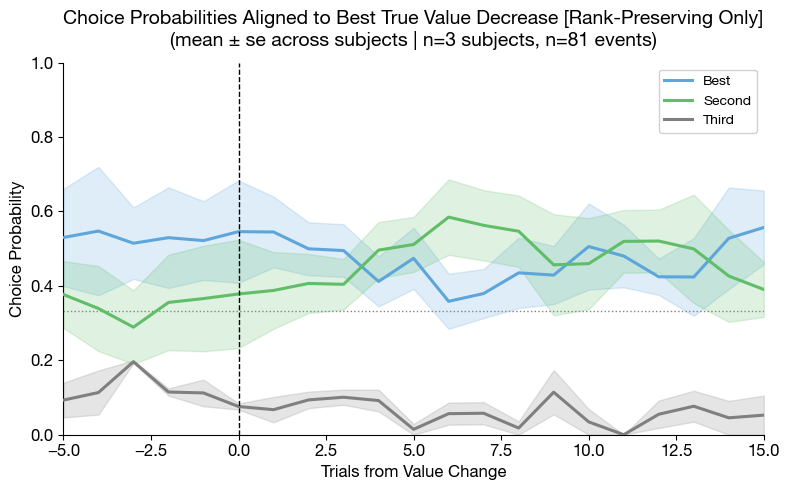

/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_2285/740074493.py:420: RuntimeWarning: Mean of empty slice
  per_subj_means[subj] = {r: np.nanmean(accum[r], axis=0) for r in ranks}


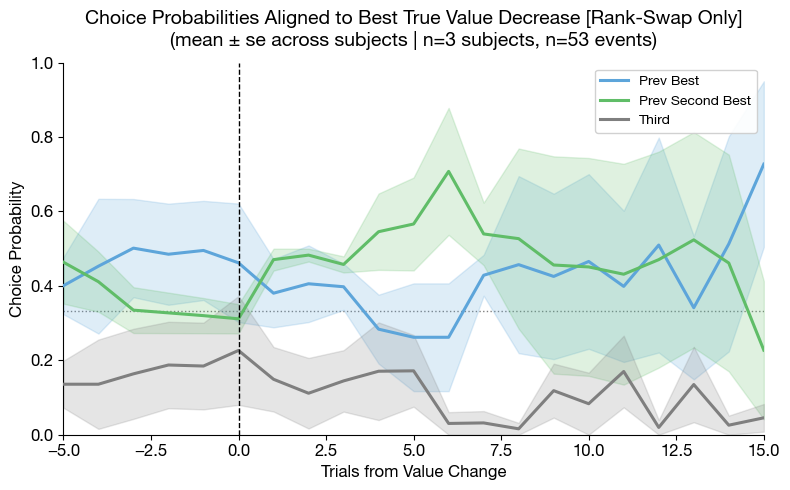

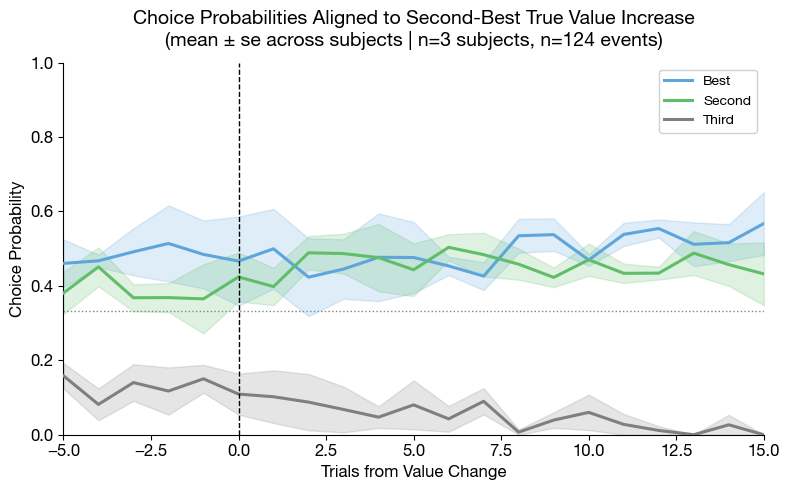

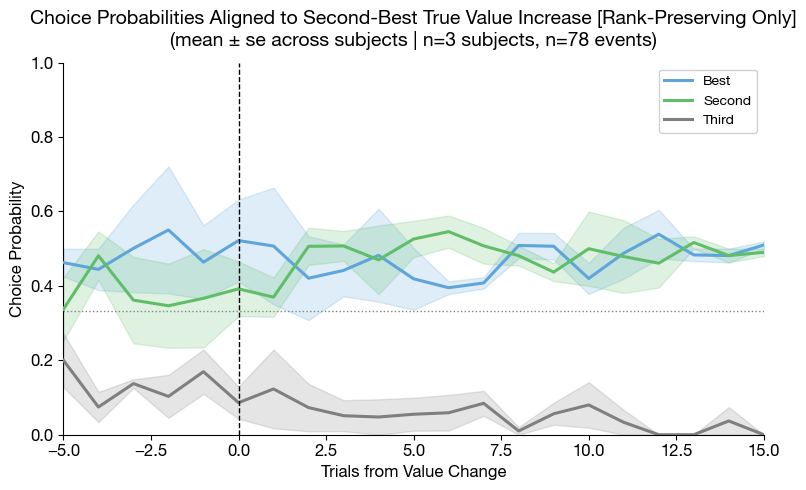

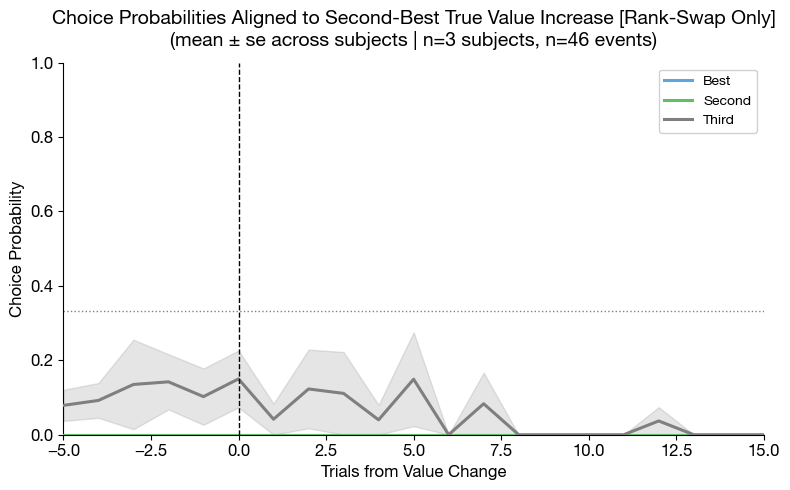

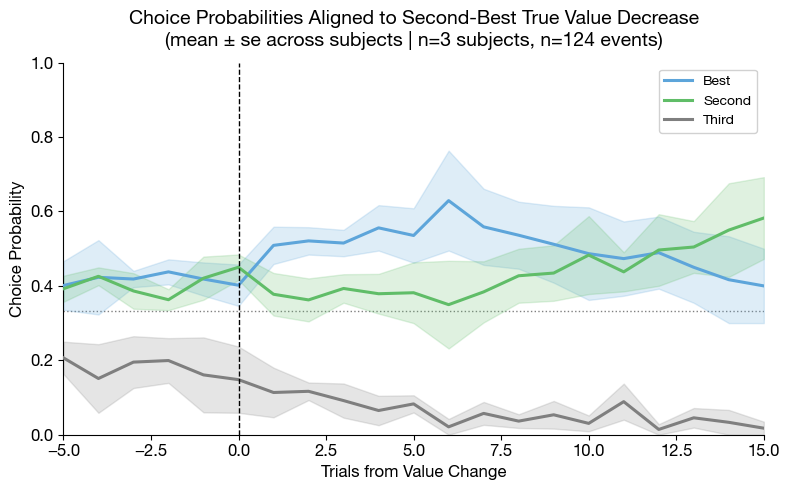

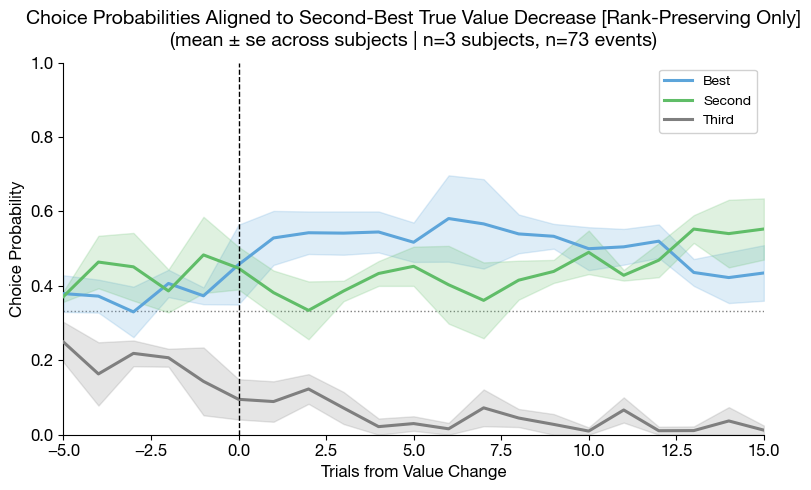

In [ ]:
subjects_trials_flat = flatten_subjects_trials(curr_subjects_trials_by_problem)

run_all_value_change_plots(subjects_trials_flat, pre=5, post=15, truncate_at_value_change=True)

In [ ]:
# Quick diagnostic for second/increase/rank_swap label detection
windows = get_value_change_windows(
    subjects_trials_flat,
    rank="second",
    direction="increase",
    pre=5, post=15,
    rank_swap_only=True,
)

# Check what labels are actually in the first few events
for subj, events in list(windows.items())[:2]:
    print(f"{subj}: {len(events)} events")
    for ev in events[:3]:
        print(f"  pre labels:  {ev['pre']}")
        print(f"  post labels: {ev['post'][:5]}...")
    print()

# Check what _aggregate_windows detects
x, per_subj, across = _aggregate_windows(windows, pre=5, post=15)
print("rank keys in across['mean']:", list(across['mean'].keys()))

MY_72_L: 8 events
  pre labels:  [None, 'third', 'third', 'third', 'third']
  post labels: ['third', 'prev_second', 'third', 'third', 'prev_best']...
  pre labels:  ['prev_second', 'prev_second', 'third', 'prev_second', 'third']
  post labels: ['third', 'prev_second', 'third', 'third', 'prev_best']...
  pre labels:  ['prev_best', 'prev_best', 'prev_best', 'prev_best', 'prev_best']
  post labels: ['prev_best', 'prev_best', 'prev_best', 'prev_best', 'prev_best']...

MY_71_R: 3 events
  pre labels:  ['prev_second', 'prev_second', 'prev_second', 'prev_second', 'prev_second']
  post labels: ['prev_second', 'prev_second', 'prev_second', 'prev_second', 'prev_second']...
  pre labels:  ['prev_best', 'prev_best', 'prev_best', 'prev_best', 'prev_best']
  post labels: ['prev_best', 'prev_best', 'prev_best', 'prev_best', 'prev_best']...
  pre labels:  ['prev_second', 'prev_second', 'prev_second', 'prev_second', 'prev_best']
  post labels: ['prev_second', 'prev_second', 'prev_second', 'prev_second'